# Flipkart Reviews Sentiment Analysis — End-to-End NLP, ML & Deep Learning
**Student project deliverable · 30,000 reviews × 25 columns · 50 implementation questions**

Target: `Sentiment` ∈ {Negative, Neutral, Positive}. Primary metric: **Macro F1**.

> **Read this first — two data findings that shape every result below**
> 1. `Sentiment` is a *deterministic function of `Rating`* (1–2 → Negative, 3 → Neutral, 4–5 → Positive) and `Sentiment_Score` is a near-copy of it. Both are **target leakage** and are excluded from all model inputs.
> 2. The review text is *template-generated*: only **30 distinct sentiment phrases** (10 per class) are combined with 32 neutral "aspect" phrases. A random train/test split therefore leaks near-identical text into the test set and produces ~100 % scores. Throughout the notebook I report the standard random split (as the brief requires) **and** a harder *unseen-phrase hold-out* that measures real generalisation.

In [1]:
import os, re, json, time, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

SEED = 42
np.random.seed(SEED); random.seed(SEED)
DATA_PATH = 'Flipkart_Reviews_Sentiment_Analysis.csv'
FIG, ART = 'figures', 'artifacts'
os.makedirs(FIG, exist_ok=True); os.makedirs(ART, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
COL = {'Negative': '#D64545', 'Neutral': '#F2A93B', 'Positive': '#2E9E6B'}
ORDER = ['Negative', 'Neutral', 'Positive']
LABEL2ID = {l: i for i, l in enumerate(ORDER)}
RESULTS = {}          # collected for the report / slides

def savefig(name):
    plt.tight_layout(); plt.savefig(f'{FIG}/{name}.png', dpi=150, bbox_inches='tight'); plt.show()

# Phase 1 — Dataset Understanding & Data Preparation

### Q1. Load the dataset: shape, columns, first 10 records

In [2]:
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
print('Columns:', list(df.columns))
df.head(10)

Shape: (30000, 25)
Columns: ['Review_ID', 'Product_ID', 'Product_Name', 'Category', 'Brand', 'Product_Price', 'Discount_Percentage', 'Selling_Price', 'Rating', 'Review_Summary', 'Review_Text', 'Sentiment', 'Sentiment_Score', 'Customer_City', 'Review_Date', 'Verified_Purchase', 'Helpful_Votes', 'Not_Helpful_Votes', 'Payment_Method', 'Purchase_Channel', 'Delivery_Partner', 'Delivery_Days', 'Customer_Device', 'Review_Confidence', 'Customer_Experience_Score']


,Review_ID,Product_ID,Product_Name,Category,Brand,Product_Price,Discount_Percentage,Selling_Price,Rating,Review_Summary,...,Verified_Purchase,Helpful_Votes,Not_Helpful_Votes,Payment_Method,Purchase_Channel,Delivery_Partner,Delivery_Days,Customer_Device,Review_Confidence,Customer_Experience_Score
0,FKR000001,PROD3286,HP 15s,Laptops,Wakefit,77090.0,15.7,64987.0,5,Loved it,...,Yes,3,2,Cash on Delivery,Website,Ekart,4,Android,0.712,1
1,FKR000002,PROD4257,LG 55 Smart TV,Televisions,Wakefit,47705.0,7.9,43936.0,5,Worth it,...,No,3,2,Credit Card,Website,Xpressbees,5,Windows,0.708,1
2,FKR000003,PROD6514,Sony WH-CH520,Audio,Realme,9835.0,12.0,8655.0,5,Great product,...,No,2,0,UPI,Website,Blue Dart,3,Windows,0.738,1
3,FKR000004,PROD5803,Deep Learning Book,Books,Prestige,1052.0,20.2,839.0,3,Average,...,No,1,0,Cash on Delivery,Mobile App,Ekart,6,Android,0.782,2
4,FKR000005,PROD5554,LG Washing Machine,Appliances,Sony,16314.0,6.7,15221.0,5,Very good,...,No,3,0,Credit Card,Website,Blue Dart,4,iOS,0.890,3
5,FKR000006,PROD8573,Acer Aspire 5,Laptops,ASUS,57394.0,2.9,55730.0,3,Could be better,...,Yes,3,2,Debit Card,Mobile App,Delhivery,6,Android,0.909,3
6,FKR000007,PROD9179,Wakefit Pillow,Home & Kitchen,ASUS,7984.0,14.0,6866.0,5,Excellent,...,No,0,1,Credit Card,Website,Delhivery,4,iOS,0.959,5
7,FKR000008,PROD4593,Bajaj Iron,Appliances,Redmi,13509.0,15.9,11361.0,5,Superb,...,No,7,3,UPI,Mobile App,Ekart,3,iOS,0.795,2
8,FKR000009,PROD9669,Milton Lunch Box,Home & Kitchen,HP,7808.0,3.8,7511.0,3,Average,...,Yes,4,3,UPI,Mobile Web,Xpressbees,3,Windows,0.752,3
9,FKR000010,PROD5315,ASUS Vivobook 15,Laptops,LG,69220.0,16.1,58076.0,4,Superb,...,Yes,5,2,Debit Card,Mobile Web,Xpressbees,5,iOS,0.832,2


### Q2. Data types and column groups

In [3]:
num_cols  = df.select_dtypes(include='number').columns.tolist()
id_cols   = ['Review_ID', 'Product_ID']
text_cols = ['Review_Summary', 'Review_Text']
date_cols = ['Review_Date']
cat_cols  = [c for c in df.columns if c not in num_cols + id_cols + text_cols + date_cols]
print(df.dtypes.to_string(), '\n')
for name, cols in [('Numerical', num_cols), ('Categorical', cat_cols), ('Identifier', id_cols), ('Text', text_cols), ('Date (stored as string)', date_cols)]:
    print(f'{name} ({len(cols)}): {cols}')

Review_ID                        str
Product_ID                       str
Product_Name                     str
Category                         str
Brand                            str
Product_Price                float64
Discount_Percentage          float64
Selling_Price                float64
Rating                         int64
Review_Summary                   str
Review_Text                      str
Sentiment                        str
Sentiment_Score              float64
Customer_City                    str
Review_Date                      str
Verified_Purchase                str
Helpful_Votes                  int64
Not_Helpful_Votes              int64
Payment_Method                   str
Purchase_Channel                 str
Delivery_Partner                 str
Delivery_Days                  int64
Customer_Device                  str
Review_Confidence            float64
Customer_Experience_Score      int64 

Numerical (10): ['Product_Price', 'Discount_Percentage', 'Selling_Price',

### Q3. Missing values

In [4]:
miss = df.isna().sum().to_frame('missing'); miss['pct'] = (miss.missing / len(df) * 100).round(2)
display(miss[miss.missing > 0])
print('Columns with no missing values:', (miss.missing == 0).sum(), 'of', len(df.columns))
RESULTS['missing'] = miss[miss.missing > 0].to_dict()['missing']

,missing,pct
Review_Summary,240,0.8
Customer_City,300,1.0
Payment_Method,150,0.5


Columns with no missing values: 22 of 25


### Q4. Duplicate detection and handling

In [5]:
dup_id    = df.Review_ID.duplicated().sum()
dup_text  = df.Review_Text.duplicated().sum()
combo     = ['Product_ID', 'Customer_City', 'Review_Date', 'Review_Text', 'Rating']
dup_combo = df.duplicated(subset=combo).sum()
dup_full  = df.drop(columns='Review_ID').duplicated().sum()
print(f'Duplicate Review_ID                : {dup_id}')
print(f'Duplicate Review_Text              : {dup_text}  ({df.Review_Text.nunique()} unique texts)')
print(f'Duplicate on {combo}: {dup_combo}')
print(f'Fully duplicated rows (ex Review_ID): {dup_full}')
RESULTS['dups'] = dict(id=int(dup_id), text=int(dup_text), unique_text=int(df.Review_Text.nunique()), combo=int(dup_combo), full=int(dup_full))

Duplicate Review_ID                : 0
Duplicate Review_Text              : 29040  (960 unique texts)
Duplicate on ['Product_ID', 'Customer_City', 'Review_Date', 'Review_Text', 'Rating']: 0
Fully duplicated rows (ex Review_ID): 0


**Decision.** `Review_ID` is unique and no row is a true duplicate (same product, city, date, text *and* rating), so **no rows are dropped**. Repeated `Review_Text` values are an artefact of template generation, not data-entry duplicates — many different customers can legitimately write the same short sentence. The consequence (near-identical text across train and test) is handled in the *evaluation design*, not by deleting data.

### Q5. Datetime conversion and feature extraction

In [6]:
df['Review_Date'] = pd.to_datetime(df['Review_Date'])
df['Year'] = df.Review_Date.dt.year; df['Month'] = df.Review_Date.dt.month
df['Day'] = df.Review_Date.dt.day;   df['DayOfWeek'] = df.Review_Date.dt.day_name()
print('Date range:', df.Review_Date.min().date(), '→', df.Review_Date.max().date())
df[['Review_Date', 'Year', 'Month', 'Day', 'DayOfWeek']].head()

Date range: 2025-01-01 → 2026-08-14


,Review_Date,Year,Month,Day,DayOfWeek
0,2025-08-17,2025,8,17,Sunday
1,2026-07-29,2026,7,29,Wednesday
2,2025-08-09,2025,8,9,Saturday
3,2026-07-20,2026,7,20,Monday
4,2026-01-25,2026,1,25,Sunday


### Q6. Basic statistics

In [7]:
stat_cols = ['Product_Price', 'Selling_Price', 'Rating', 'Discount_Percentage', 'Delivery_Days', 'Helpful_Votes']
df[stat_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Product_Price,30000.0,27499.71,30744.12,150.0,3621.75,11510.0,46121.00,119988.0
Selling_Price,30000.0,22514.37,25478.06,95.0,2945.75,9456.0,37233.75,119941.0
Rating,30000.0,3.80,1.30,1.0,3.00,4.0,5.00,5.0
Discount_Percentage,30000.0,18.07,9.62,0.0,11.20,17.9,24.60,54.0
Delivery_Days,30000.0,4.07,1.92,1.0,3.00,4.0,5.00,12.0
Helpful_Votes,30000.0,3.19,1.82,0.0,2.00,3.0,4.00,14.0


### Q7. Unrealistic values

In [8]:
calc_sell = (df.Product_Price * (1 - df.Discount_Percentage / 100)).round()
checks = {
 'Product_Price <= 0'                       : (df.Product_Price <= 0).sum(),
 'Selling_Price <= 0'                       : (df.Selling_Price <= 0).sum(),
 'Selling_Price > Product_Price'            : (df.Selling_Price > df.Product_Price).sum(),
 'Selling_Price != Price x (1-discount) (±2)': ((calc_sell - df.Selling_Price).abs() > 2).sum(),
 'Discount outside 0-100 %'                 : ((df.Discount_Percentage < 0) | (df.Discount_Percentage > 100)).sum(),
 'Discount = 0 % (valid, just no offer)'    : (df.Discount_Percentage == 0).sum(),
 'Rating outside 1-5'                       : (~df.Rating.between(1, 5)).sum(),
 'Delivery_Days <= 0'                       : (df.Delivery_Days <= 0).sum(),
 'Delivery_Days >= 10 (slow, plausible)'    : (df.Delivery_Days >= 10).sum(),
 'Experience score outside 1-5'             : (~df.Customer_Experience_Score.between(1, 5)).sum(),
 'Review date in the future'                : (df.Review_Date > pd.Timestamp.today()).sum(),
 'Review_Confidence outside 0-1'            : (~df.Review_Confidence.between(0, 1)).sum(),
}
chk = pd.Series(checks, name='rows'); display(chk.to_frame())
bp = df.groupby('Product_Name').Brand.nunique()
print(f'\nSemantic check: {(bp > 1).sum()} of {len(bp)} product names appear under more than one brand '
      f'(e.g. "HP 15s" sold by Wakefit) — a synthetic-data artefact. Brand/Product are kept for EDA only.')
RESULTS['invalid_checks'] = {k: int(v) for k, v in checks.items()}

,rows
Product_Price <= 0,0
Selling_Price <= 0,0
Selling_Price > Product_Price,0
Selling_Price != Price x (1-discount) (±2),0
Discount outside 0-100 %,0
"Discount = 0 % (valid, just no offer)",1068
Rating outside 1-5,0
Delivery_Days <= 0,0
"Delivery_Days >= 10 (slow, plausible)",76
Experience score outside 1-5,0



Semantic check: 40 of 40 product names appear under more than one brand (e.g. "HP 15s" sold by Wakefit) — a synthetic-data artefact. Brand/Product are kept for EDA only.


### Q7b. Dataset structure check — why this dataset is easy (important)

In [9]:
parts = df.Review_Text.str.rsplit(', ', n=1, expand=True)
df['Review_Head'], df['Review_Tail'] = parts[0], parts[1]       # sentiment phrase, neutral aspect phrase
print('Distinct sentiment phrases (heads):', df.Review_Head.nunique(), '| distinct aspect phrases (tails):', df.Review_Tail.nunique())
print('Heads per class:', df.groupby('Sentiment').Review_Head.nunique().to_dict())
print('Tails per class:', df.groupby('Sentiment').Review_Tail.nunique().to_dict())
print('Heads appearing under >1 sentiment:', int((df.groupby('Review_Head').Sentiment.nunique() > 1).sum()))
print('Rating -> Sentiment is deterministic:', df.groupby('Rating').Sentiment.nunique().max() == 1)
print('Unique Combined (summary+text) strings:', (df.Review_Summary.fillna('') + '|' + df.Review_Text).nunique())
print()
for s in ORDER: print(s, '→', df[df.Sentiment == s].Review_Head.drop_duplicates().head(4).tolist())
print('\nExample of a contradictory review (negative head + positive aspect tail):')
print(df[(df.Sentiment == 'Negative') & df.Review_Tail.str.contains('good|great|comfortable')].Review_Text.iloc[0])
RESULTS['n_heads'] = int(df.Review_Head.nunique()); RESULTS['n_tails'] = int(df.Review_Tail.nunique())

Distinct sentiment phrases (heads): 30 | distinct aspect phrases (tails): 32
Heads per class: {'Negative': 10, 'Neutral': 10, 'Positive': 10}
Tails per class: {'Negative': 32, 'Neutral': 32, 'Positive': 32}
Heads appearing under >1 sentiment: 0
Rating -> Sentiment is deterministic: True
Unique Combined (summary+text) strings: 6093

Negative → ['waste of money, do not recommend', 'very poor experience with this product', 'expected much better quality', 'delivery was late and packaging was damaged']
Neutral → ['quality is neither very good nor very bad', 'decent product but nothing special', 'received the product and it is usable', 'okay purchase, meets basic requirements']
Positive → ['good product, works perfectly', 'perfect purchase, loved it', 'quality is superb and performance is great', 'really happy with the purchase']

Example of a contradictory review (negative head + positive aspect tail):


very poor experience with this product, fit is comfortable.


### Q8. Cleaned dataset

In [10]:
df_clean = df.copy()
df_clean['Review_Summary']  = df_clean.Review_Summary.fillna('')
df_clean['Customer_City']   = df_clean.Customer_City.fillna('Unknown')
df_clean['Payment_Method']  = df_clean.Payment_Method.fillna('Unknown')
assert df_clean.isna().sum().sum() == 0
assert not df_clean.Review_ID.duplicated().any()
df_clean.to_csv('Flipkart_Reviews_Cleaned.csv', index=False)
print('Cleaned shape:', df_clean.shape, '| remaining nulls:', int(df_clean.isna().sum().sum()))
print('Handling: blank Review_Summary -> empty string (text model still has Review_Text); missing city/payment -> "Unknown"; no rows dropped.')

Cleaned shape: (30000, 31) | remaining nulls: 0
Handling: blank Review_Summary -> empty string (text model still has Review_Text); missing city/payment -> "Unknown"; no rows dropped.


# Phase 2 — Exploratory Data Analysis

### Q9. Sentiment distribution

           count   pct
Sentiment             
Negative    5310  17.7
Neutral     6019  20.1
Positive   18671  62.2


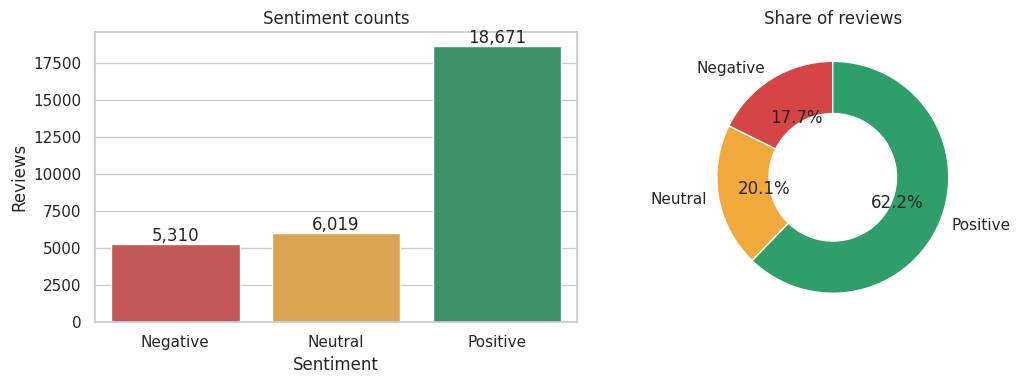

In [11]:
vc = df_clean.Sentiment.value_counts().reindex(ORDER); pct = (vc / len(df_clean) * 100).round(1)
print(pd.DataFrame({'count': vc, 'pct': pct}))
RESULTS['sentiment_pct'] = pct.to_dict(); RESULTS['sentiment_n'] = vc.to_dict()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=vc.index, y=vc.values, palette=[COL[s] for s in vc.index], ax=ax[0])
for i, v in enumerate(vc.values): ax[0].text(i, v + 200, f'{v:,}', ha='center')
ax[0].set_title('Sentiment counts'); ax[0].set_ylabel('Reviews')
ax[1].pie(vc.values, labels=vc.index, autopct='%1.1f%%', colors=[COL[s] for s in vc.index], startangle=90, wedgeprops=dict(width=.45))
ax[1].set_title('Share of reviews'); savefig('q09_sentiment_distribution')

### Q10. Rating vs Sentiment (and the leakage it implies)

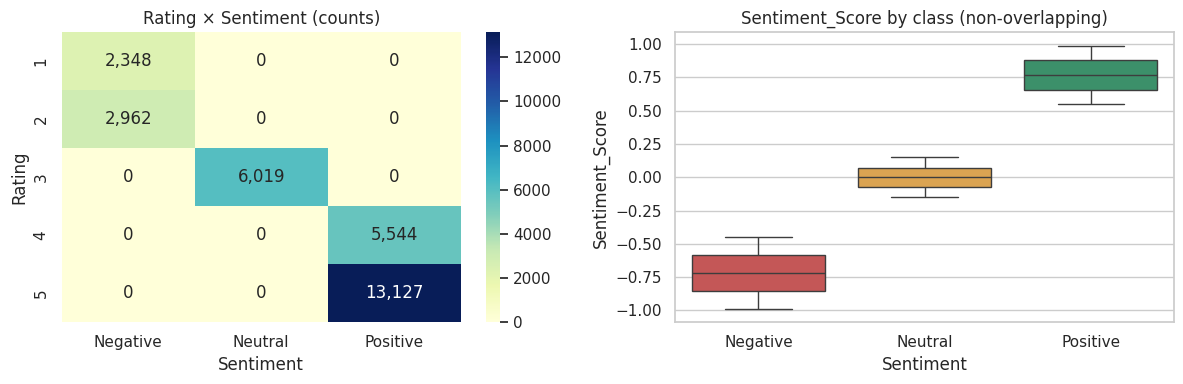

Corr(Rating, Sentiment_Score) = 0.926
=> Rating and Sentiment_Score perfectly separate the classes. They are LEAKAGE and are excluded from model features.


In [12]:
ct = pd.crosstab(df_clean.Rating, df_clean.Sentiment)[ORDER]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(ct, annot=True, fmt=',', cmap='YlGnBu', ax=ax[0]); ax[0].set_title('Rating × Sentiment (counts)')
sns.boxplot(data=df_clean, x='Sentiment', y='Sentiment_Score', order=ORDER, palette=COL, ax=ax[1]); ax[1].set_title('Sentiment_Score by class (non-overlapping)')
savefig('q10_rating_vs_sentiment')
print('Corr(Rating, Sentiment_Score) =', round(df_clean.Rating.corr(df_clean.Sentiment_Score), 3))
print('=> Rating and Sentiment_Score perfectly separate the classes. They are LEAKAGE and are excluded from model features.')

### Q11. Categories with the most reviews

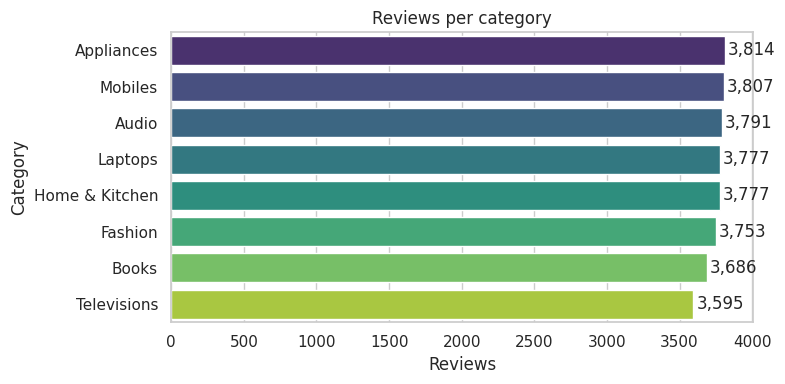

Category
Appliances        3814
Mobiles           3807
Audio             3791
Laptops           3777
Home & Kitchen    3777
Fashion           3753
Books             3686
Televisions       3595


In [13]:
cat_n = df_clean.Category.value_counts()
plt.figure(figsize=(8, 4)); sns.barplot(x=cat_n.values, y=cat_n.index, palette='viridis')
for i, v in enumerate(cat_n.values): plt.text(v + 20, i, f'{v:,}', va='center')
plt.title('Reviews per category'); plt.xlabel('Reviews'); savefig('q11_category_reviews')
print(cat_n.to_string()); RESULTS['top_category'] = [cat_n.index[0], int(cat_n.iloc[0])]

### Q12. Top 10 brands by review count

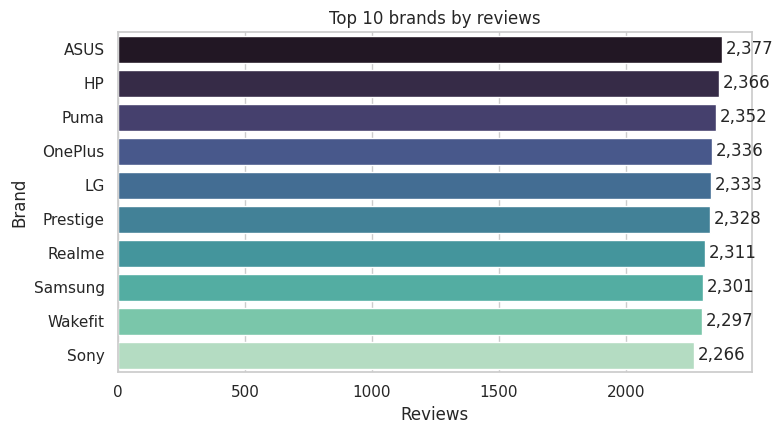

Brand
ASUS        2377
HP          2366
Puma        2352
OnePlus     2336
LG          2333
Prestige    2328
Realme      2311
Samsung     2301
Wakefit     2297
Sony        2266


In [14]:
br = df_clean.Brand.value_counts().head(10)
plt.figure(figsize=(8, 4.5)); sns.barplot(x=br.values, y=br.index, palette='mako')
for i, v in enumerate(br.values): plt.text(v + 15, i, f'{v:,}', va='center')
plt.title('Top 10 brands by reviews'); plt.xlabel('Reviews'); savefig('q12_top_brands')
print(br.to_string())

### Q13. Average rating per category

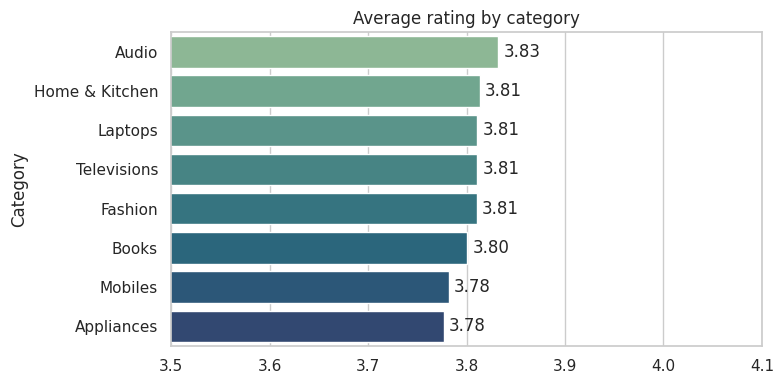

Category
Audio             3.832
Home & Kitchen    3.814
Laptops           3.811
Televisions       3.811
Fashion           3.810
Books             3.801
Mobiles           3.782
Appliances        3.777
Spread (max-min): 0.055


In [15]:
cr = df_clean.groupby('Category').Rating.mean().sort_values(ascending=False)
plt.figure(figsize=(8, 4)); sns.barplot(x=cr.values, y=cr.index, palette='crest'); plt.xlim(3.5, 4.1)
for i, v in enumerate(cr.values): plt.text(v + .005, i, f'{v:.2f}', va='center')
plt.title('Average rating by category'); savefig('q13_avg_rating_category')
print(cr.round(3).to_string()); print('Spread (max-min):', round(cr.max() - cr.min(), 3))

### Q14. Average selling price per category

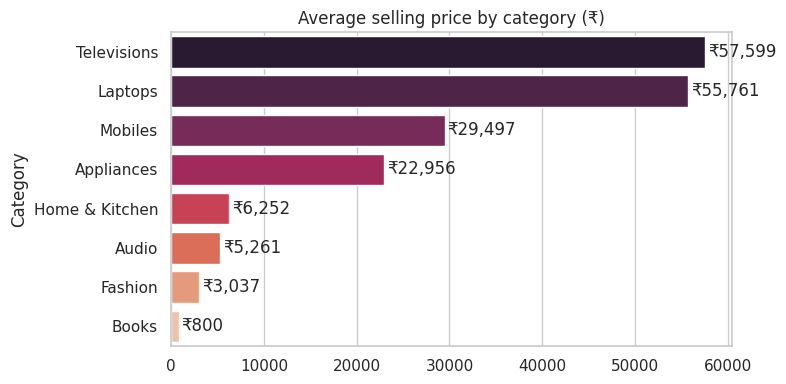

Category
Televisions       57599.0
Laptops           55761.0
Mobiles           29497.0
Appliances        22956.0
Home & Kitchen     6252.0
Audio              5261.0
Fashion            3037.0
Books               800.0


In [16]:
sp = df_clean.groupby('Category').Selling_Price.mean().sort_values(ascending=False)
plt.figure(figsize=(8, 4)); sns.barplot(x=sp.values, y=sp.index, palette='rocket')
for i, v in enumerate(sp.values): plt.text(v + 300, i, f'₹{v:,.0f}', va='center')
plt.title('Average selling price by category (₹)'); savefig('q14_avg_price_category')
print(sp.round(0).to_string())

### Q15. Discount vs sentiment

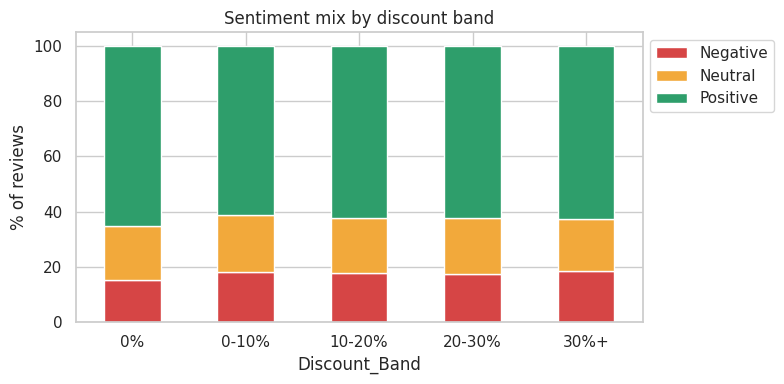

Sentiment      Negative  Neutral  Positive
Discount_Band                             
0%                 15.3     19.7      65.1
0-10%              18.0     20.8      61.3
10-20%             17.9     19.9      62.3
20-30%             17.3     20.4      62.2
30%+               18.5     18.7      62.8

chi-square p = 0.101 | Spearman(discount, sentiment) = 0.002


In [17]:
from scipy.stats import chi2_contingency, spearmanr
bins = [-0.1, 0.01, 10, 20, 30, 60]; labels = ['0%', '0-10%', '10-20%', '20-30%', '30%+']
df_clean['Discount_Band'] = pd.cut(df_clean.Discount_Percentage, bins=bins, labels=labels)
dsh = pd.crosstab(df_clean.Discount_Band, df_clean.Sentiment, normalize='index')[ORDER] * 100
dsh.plot(kind='bar', stacked=True, color=[COL[s] for s in ORDER], figsize=(8, 4)); plt.ylabel('% of reviews'); plt.xticks(rotation=0)
plt.title('Sentiment mix by discount band'); plt.legend(title='', bbox_to_anchor=(1, 1)); savefig('q15_discount_sentiment')
chi2, p, _, _ = chi2_contingency(pd.crosstab(df_clean.Discount_Band, df_clean.Sentiment))
rho, _ = spearmanr(df_clean.Discount_Percentage, df_clean.Sentiment.map(LABEL2ID))
print(dsh.round(1)); print(f'\nchi-square p = {p:.3f} | Spearman(discount, sentiment) = {rho:.3f}')
RESULTS['discount'] = dict(p=float(p), rho=float(rho))

### Q16. Delivery days vs Customer Experience Score

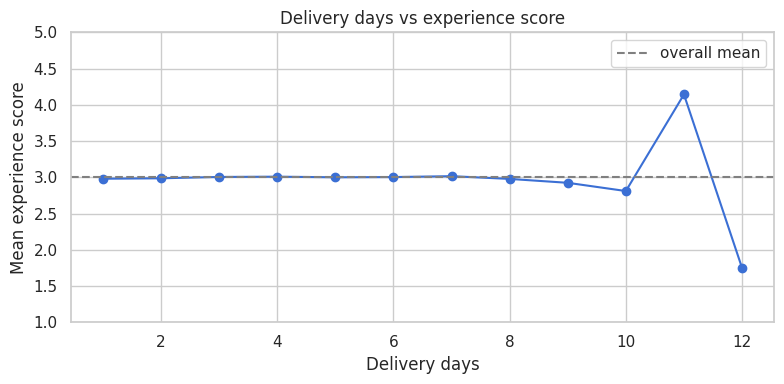

Spearman rho = 0.003 (p = 0.594) -> no relationship in this dataset


In [18]:
g = df_clean.groupby('Delivery_Days').Customer_Experience_Score.agg(['mean', 'count']).reset_index()
fig, ax = plt.subplots(figsize=(8, 4)); ax.plot(g.Delivery_Days, g['mean'], marker='o', color='#3B6FD4')
ax.axhline(df_clean.Customer_Experience_Score.mean(), ls='--', c='grey', label='overall mean'); ax.set_ylim(1, 5)
ax.set_xlabel('Delivery days'); ax.set_ylabel('Mean experience score'); ax.set_title('Delivery days vs experience score'); ax.legend(); savefig('q16_delivery_experience')
rho, p = spearmanr(df_clean.Delivery_Days, df_clean.Customer_Experience_Score)
print(f'Spearman rho = {rho:.3f} (p = {p:.3f}) -> no relationship in this dataset'); RESULTS['delivery_exp_rho'] = float(rho)

### Q17. Verified vs non-verified purchases

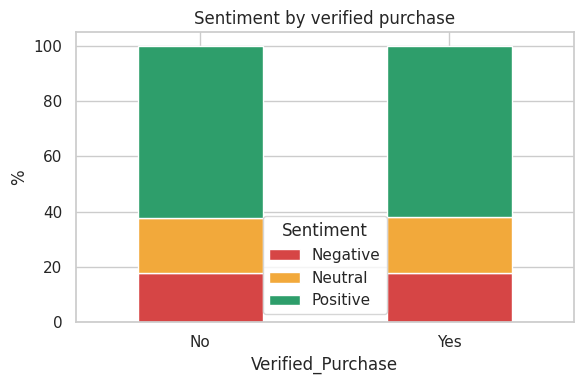

Sentiment          Negative  Neutral  Positive
Verified_Purchase                             
No                     17.7     19.9      62.4
Yes                    17.7     20.2      62.0
chi-square p = 0.720 -> no significant difference


In [19]:
vs = pd.crosstab(df_clean.Verified_Purchase, df_clean.Sentiment, normalize='index')[ORDER] * 100
vs.plot(kind='bar', stacked=True, color=[COL[s] for s in ORDER], figsize=(6, 4)); plt.xticks(rotation=0); plt.ylabel('%'); plt.title('Sentiment by verified purchase')
savefig('q17_verified_sentiment')
chi2, p, _, _ = chi2_contingency(pd.crosstab(df_clean.Verified_Purchase, df_clean.Sentiment))
print(vs.round(1)); print(f'chi-square p = {p:.3f} -> {"significant" if p < .05 else "no significant difference"}'); RESULTS['verified_p'] = float(p)

### Q18. Most helpful reviews

In [20]:
top = df_clean.sort_values(['Helpful_Votes', 'Not_Helpful_Votes'], ascending=[False, True]).head(10)
display(top[['Review_ID', 'Helpful_Votes', 'Not_Helpful_Votes', 'Sentiment', 'Review_Summary', 'Review_Text']])
hv = df_clean[df_clean.Helpful_Votes >= df_clean.Helpful_Votes.quantile(.95)]
print(f'Top-5% helpful reviews (>= {int(df_clean.Helpful_Votes.quantile(.95))} votes, n={len(hv):,}) sentiment mix (%):')
print((hv.Sentiment.value_counts(normalize=True)[ORDER] * 100).round(1).to_dict())
print('Overall mix (%):', (df_clean.Sentiment.value_counts(normalize=True)[ORDER] * 100).round(1).to_dict())
print('Mean helpful votes by sentiment:', df_clean.groupby('Sentiment').Helpful_Votes.mean().round(2).to_dict())

,Review_ID,Helpful_Votes,Not_Helpful_Votes,Sentiment,Review_Summary,Review_Text
14890,FKR014891,14,3,Negative,Waste of money,"delivery was late and packaging was damaged, b..."
1390,FKR001391,12,0,Negative,Bad,"very poor experience with this product, colour..."
14528,FKR014529,12,0,Positive,Worth it,"really happy with the purchase, sound could be..."
2034,FKR002035,12,1,Negative,Defective,"waste of money, do not recommend, design is pr..."
10062,FKR010063,12,1,Negative,Waste of money,"received a defective product, instructions wer..."
23760,FKR023761,12,1,Negative,Disappointed,"waste of money, do not recommend, battery back..."
25066,FKR025067,12,1,Positive,Awesome,"excellent product and very good quality, clean..."
28980,FKR028981,12,1,Positive,Worth it,"really happy with the purchase, installation w..."
3133,FKR003134,12,2,Negative,Defective,"very poor experience with this product, instal..."
11801,FKR011802,12,2,Neutral,Average,"average quality for the price, fan noise is no..."


Top-5% helpful reviews (>= 6 votes, n=3,305) sentiment mix (%):
{'Negative': 33.9, 'Neutral': 16.2, 'Positive': 49.9}
Overall mix (%): {'Negative': 17.7, 'Neutral': 20.1, 'Positive': 62.2}
Mean helpful votes by sentiment: {'Negative': 3.98, 'Neutral': 3.03, 'Positive': 3.01}


### Q19. Word frequency by sentiment

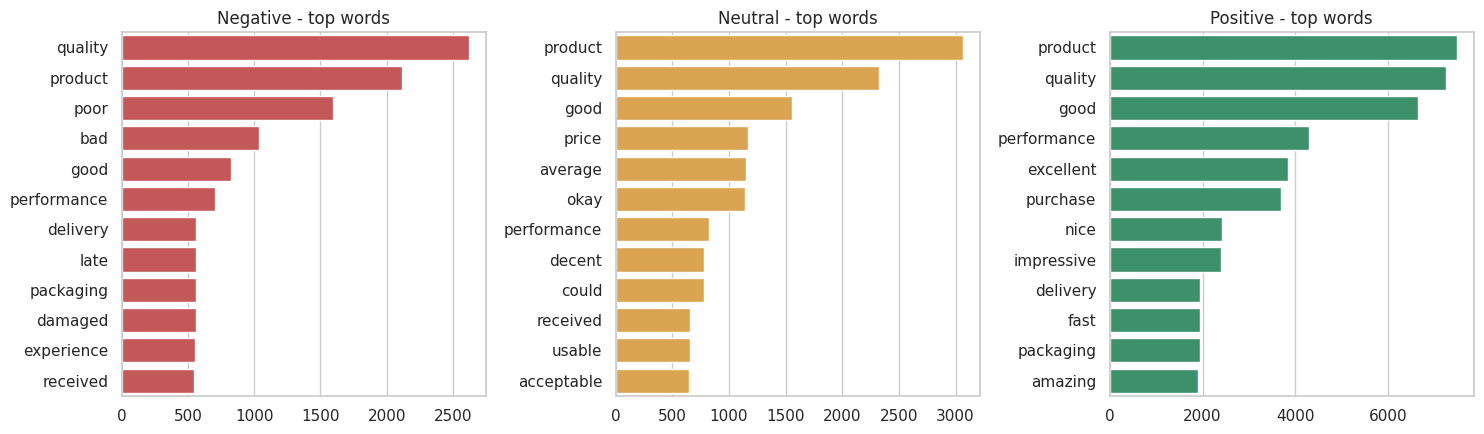

Negative ['quality', 'product', 'poor', 'bad', 'good', 'performance', 'delivery', 'late', 'packaging', 'damaged', 'experience', 'received']
Neutral ['product', 'quality', 'good', 'price', 'average', 'okay', 'performance', 'decent', 'could', 'received', 'usable', 'acceptable']
Positive ['product', 'quality', 'good', 'performance', 'excellent', 'purchase', 'nice', 'impressive', 'delivery', 'fast', 'packaging', 'amazing']

Note: neutral aspect words (e.g. "good", "quality") appear in every class — the sentiment signal sits in the head phrase.


In [21]:
from collections import Counter
import nlp_utils as nu
def top_words(series, n=12):
    c = Counter()
    for t, k in series.value_counts().items():          # tokenise each unique text once, weight by frequency
        for w in nu.tokenize(nu.clean(t)):
            if w not in nu.STOP and len(w) > 2: c[w] += k
    return c.most_common(n)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5)); freq = {}
for a, s in zip(ax, ORDER):
    words = top_words(df_clean[df_clean.Sentiment == s].Review_Text)
    freq[s] = words; w, c = zip(*words)
    sns.barplot(x=list(c), y=list(w), color=COL[s], ax=a); a.set_title(f'{s} - top words')
savefig('q19_word_frequency')
for s in ORDER: print(s, [w for w, _ in freq[s]])
print('\nNote: neutral aspect words (e.g. "good", "quality") appear in every class — the sentiment signal sits in the head phrase.')

### EDA dashboard (one-page summary)

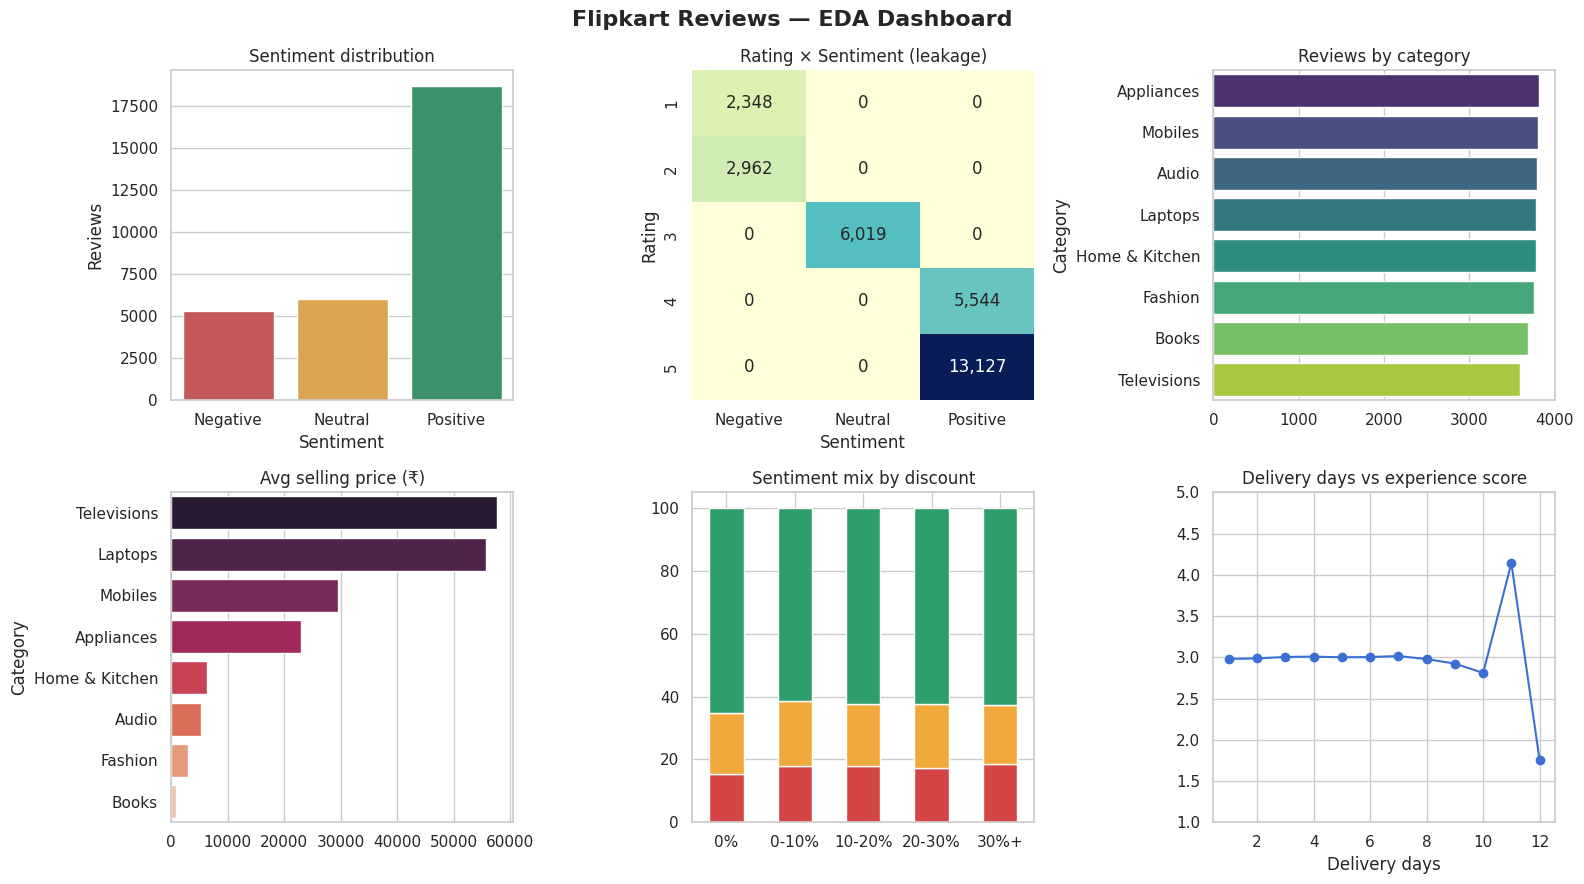

In [22]:
fig = plt.figure(figsize=(16, 9)); gs = fig.add_gridspec(2, 3)
ax = fig.add_subplot(gs[0, 0]); sns.barplot(x=vc.index, y=vc.values, palette=[COL[s] for s in vc.index], ax=ax); ax.set_title('Sentiment distribution'); ax.set_ylabel('Reviews')
ax = fig.add_subplot(gs[0, 1]); sns.heatmap(ct, annot=True, fmt=',', cmap='YlGnBu', ax=ax, cbar=False); ax.set_title('Rating × Sentiment (leakage)')
ax = fig.add_subplot(gs[0, 2]); sns.barplot(x=cat_n.values, y=cat_n.index, palette='viridis', ax=ax); ax.set_title('Reviews by category')
ax = fig.add_subplot(gs[1, 0]); sns.barplot(x=sp.values, y=sp.index, palette='rocket', ax=ax); ax.set_title('Avg selling price (₹)')
ax = fig.add_subplot(gs[1, 1]); dsh.plot(kind='bar', stacked=True, color=[COL[s] for s in ORDER], ax=ax, legend=False); ax.set_title('Sentiment mix by discount'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=0)
ax = fig.add_subplot(gs[1, 2]); ax.plot(g.Delivery_Days, g['mean'], marker='o', color='#3B6FD4'); ax.set_ylim(1, 5); ax.set_title('Delivery days vs experience score'); ax.set_xlabel('Delivery days')
fig.suptitle('Flipkart Reviews — EDA Dashboard', fontsize=16, fontweight='bold'); savefig('eda_dashboard')

# Phase 3 — NLP Text Preprocessing

All cleaning functions live in `nlp_utils.py` so the notebook and the final prediction pipeline use identical preprocessing.

In [23]:
import nlp_utils as nu
print(open('nlp_utils.py').read()[:1200], '...')

"""Shared NLP preprocessing used by the notebook and the standalone prediction pipeline."""
import re
import nltk
for _pkg in ("punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"):
    nltk.download(_pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

STOP = set(stopwords.words("english"))
NEGATIONS = {"no", "nor", "not", "never"}
_stemmer, _lemmer = PorterStemmer(), WordNetLemmatizer()


def combine(summary, text):
    """Q20: Review_Summary + Review_Text -> Combined_Review."""
    summary = "" if summary is None or summary != summary else str(summary)
    return f"{summary}. {text}".strip(". ").strip()


def clean(text):
    """Q21: lowercase, drop punctuation/symbols, collapse whitespace."""
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def tokenize(text):
    """Q22: NLTK word tokenisation."""
    return word_t

### Q20. Combined_Review

In [24]:
df_clean['Combined_Review'] = [nu.combine(s, t) for s, t in zip(df_clean.Review_Summary, df_clean.Review_Text)]
df_clean[['Review_Summary', 'Review_Text', 'Combined_Review']].head(5)

,Review_Summary,Review_Text,Combined_Review
0,Loved it,"good product, works perfectly, keyboard feels ...","Loved it. good product, works perfectly, keybo..."
1,Worth it,"perfect purchase, loved it, picture quality is...","Worth it. perfect purchase, loved it, picture ..."
2,Great product,"good product, works perfectly, bass is good.","Great product. good product, works perfectly, ..."
3,Average,"quality is neither very good nor very bad, con...",Average. quality is neither very good nor very...
4,Very good,"quality is superb and performance is great, bu...",Very good. quality is superb and performance i...


### Q21–Q22. Lowercase / punctuation removal and tokenisation

In [25]:
# Preprocess each UNIQUE string once and map back (6k unique strings vs 30k rows).
uniq = pd.Series(df_clean.Combined_Review.unique())
cleaned = {u: nu.clean(u) for u in uniq}
toks    = {u: nu.tokenize(cleaned[u]) for u in uniq}
df_clean['clean'] = df_clean.Combined_Review.map(cleaned)
df_clean['tokens'] = df_clean.Combined_Review.map(toks)
print('Apostrophes in raw text:', int(df_clean.Combined_Review.str.contains("'").sum()), '(none -> simple regex cleaning is safe)')
for i in range(3): print(repr(df_clean.Combined_Review.iloc[i]), '\n   ->', df_clean.tokens.iloc[i])

Apostrophes in raw text: 0 (none -> simple regex cleaning is safe)
'Loved it. good product, works perfectly, keyboard feels comfortable' 
   -> ['loved', 'it', 'good', 'product', 'works', 'perfectly', 'keyboard', 'feels', 'comfortable']
'Worth it. perfect purchase, loved it, picture quality is sharp' 
   -> ['worth', 'it', 'perfect', 'purchase', 'loved', 'it', 'picture', 'quality', 'is', 'sharp']
'Great product. good product, works perfectly, bass is good' 
   -> ['great', 'product', 'good', 'product', 'works', 'perfectly', 'bass', 'is', 'good']


### Q23. Stop-word removal — before vs after

In [26]:
df_clean['tokens_nostop'] = df_clean.Combined_Review.map({u: nu.remove_stop(toks[u]) for u in uniq})
before = df_clean.tokens.map(len); after = df_clean.tokens_nostop.map(len)
vb = len({w for t in df_clean.tokens for w in t}); va = len({w for t in df_clean.tokens_nostop for w in t})
print(pd.DataFrame({'avg tokens/review': [before.mean(), after.mean()], 'total tokens': [before.sum(), after.sum()], 'vocabulary': [vb, va]}, index=['before', 'after']).round(2))
print(f'Tokens removed: {(1 - after.sum() / before.sum()) * 100:.1f}%')
neg_removed = sum(any(w in nu.NEGATIONS for w in t) for t in df_clean.tokens) - sum(any(w in nu.NEGATIONS for w in t) for t in df_clean.tokens_nostop)
print(f'Reviews that lose a negation word (no/not/nor) under standard stop-word removal: {neg_removed:,} -> negation-safe variant keeps them.')

        avg tokens/review  total tokens  vocabulary
before              10.54        316291         140
after                7.45        223444         116
Tokens removed: 29.4%
Reviews that lose a negation word (no/not/nor) under standard stop-word removal: 2,354 -> negation-safe variant keeps them.


### Q24. Porter stemming

In [27]:
df_clean['tokens_stem'] = df_clean.Combined_Review.map({u: nu.stem(nu.remove_stop(toks[u], keep_negations=True)) for u in uniq})
for t in df_clean.sample(5, random_state=3).index: print(' '.join(df_clean.tokens_nostop[t]), '\n   ->', ' '.join(df_clean.tokens_stem[t]))

great product quality superb performance great bass good 
   -> great product qualiti superb perform great bass good
great product nice product impressive performance camera quality impressive 
   -> great product nice product impress perform camera qualiti impress
poor quality received defective product fabric quality nice 
   -> poor qualiti receiv defect product fabric qualiti nice
awesome good product works perfectly chapters well organized 
   -> awesom good product work perfectli chapter well organ
loved quality superb performance great size accurate 
   -> love qualiti superb perform great size accur


### Q25. Lemmatization vs stemming (20 samples)

In [28]:
df_clean['tokens_lemma'] = df_clean.Combined_Review.map({u: nu.lemmatize(nu.remove_stop(toks[u], keep_negations=True)) for u in uniq})
s20 = df_clean.drop_duplicates('Combined_Review').sample(20, random_state=7)
cmp = pd.DataFrame({'original': s20.clean, 'stemmed': s20.tokens_stem.map(' '.join), 'lemmatized': s20.tokens_lemma.map(' '.join)}); display(cmp)
vs_, vl_ = len({w for t in df_clean.tokens_stem for w in t}), len({w for t in df_clean.tokens_lemma for w in t})
print(f'Vocabulary — stemmed: {vs_} | lemmatized: {vl_}. Stems like "disappoint"/"satisfi" are not real words; lemmas stay readable (better for explainability).')

,original,stemmed,lemmatized
4814,could be better average quality for the price ...,could better averag qualiti price display bright,could better average quality price display bright
1487,awesome value for money and highly recommended...,awesom valu money highli recommend heat notic,awesome value money highly recommend heat noti...
5834,worth it nice product with impressive performa...,worth nice product impress perform power consu...,worth nice product impressive performance powe...
4200,waste of money expected much better quality co...,wast money expect much better qualiti colour l...,waste money expect much better quality colour ...
284,worth it quality is superb and performance is ...,worth qualiti superb perform great instruct clear,worth quality superb performance great instruc...
7361,disappointed quality is poor and performance i...,disappoint qualiti poor perform bad materi fee...,disappoint quality poor performance bad materi...
1826,very good quality is superb and performance is...,good qualiti superb perform great batteri life...,good quality superb performance great battery ...
4079,average product is fine but could be better co...,averag product fine could better content use,average product fine could better content useful
15179,okay average quality for the price sound could...,okay averag qualiti price sound could louder,okay average quality price sound could louder
13030,good enough product is okay and works as expec...,good enough product okay work expect pictur qu...,good enough product okay work expect picture q...


Vocabulary — stemmed: 116 | lemmatized: 116. Stems like "disappoint"/"satisfi" are not real words; lemmas stay readable (better for explainability).


### Q26. Numeric tokens, extra spaces, stray characters

In [29]:
n_num = sum(sum(w.isdigit() for w in t) for t in df_clean.tokens)
n_sp  = int(df_clean.Combined_Review.str.contains(r'\s{2,}').sum())
n_sym = int(df_clean.Combined_Review.str.contains(r'[^A-Za-z0-9\s.,]').sum())
print(f'Numeric tokens: {n_num} | rows with repeated spaces: {n_sp} | rows with unusual symbols: {n_sym}')
print('The functions remove_numeric() and clean() still run in the pipeline so unseen real-world reviews are handled safely.')

Numeric tokens: 0 | rows with repeated spaces: 0 | rows with unusual symbols: 0
The functions remove_numeric() and clean() still run in the pipeline so unseen real-world reviews are handled safely.


### Q27. Length by sentiment

,n_words,n_chars
Sentiment,,
Negative,10.80,66.84
Neutral,10.42,63.97
Positive,10.51,68.18


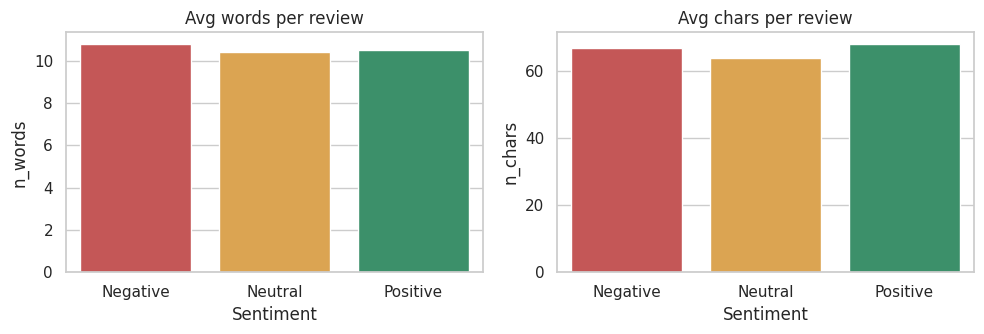

In [30]:
df_clean['n_words'] = df_clean.tokens.map(len); df_clean['n_chars'] = df_clean.clean.str.len()
ls = df_clean.groupby('Sentiment')[['n_words', 'n_chars']].mean().reindex(ORDER).round(2); display(ls)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, c in zip(ax, ['n_words', 'n_chars']): sns.barplot(x=ls.index, y=ls[c], palette=COL, ax=a); a.set_title(f'Avg {c[2:]} per review')
savefig('q27_length_by_sentiment'); RESULTS['length_by_sentiment'] = ls.to_dict()

### Q28. Compare cleaned representations and choose one for modelling

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score, StratifiedKFold
df_clean['text_clean'] = df_clean.tokens.map(' '.join)
df_clean['text_nostop'] = df_clean.tokens_nostop.map(' '.join)
df_clean['text_stem'] = df_clean.tokens_stem.map(' '.join)
df_clean['text_lemma'] = df_clean.tokens_lemma.map(' '.join)
from sklearn.pipeline import make_pipeline
y = df_clean.Sentiment.map(LABEL2ID).values; groups = df_clean.Review_Head.values
rows = []
for v in nu.VARIANTS:
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000))
    rnd = cross_val_score(pipe, df_clean[v], y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='f1_macro').mean()
    grp = cross_val_score(pipe, df_clean[v], y, cv=GroupKFold(5), groups=groups, scoring='f1_macro').mean()
    rows.append(dict(variant=v, vocab=len({w for s in df_clean[v] for w in s.split()}), avg_tokens=df_clean[v].str.split().map(len).mean(), macroF1_random_cv=rnd, macroF1_unseen_phrase_cv=grp))
var_df = pd.DataFrame(rows).set_index('variant').round(4); display(var_df)
best_var = var_df.macroF1_unseen_phrase_cv.idxmax()
near = var_df[var_df.macroF1_unseen_phrase_cv >= var_df.macroF1_unseen_phrase_cv.max() - 0.002].index.tolist()
TEXT_COL = next(v for v in ['text_clean', 'text_lemma', 'text_stem', 'text_nostop'] if v in near)   # prefer negation-preserving, readable text
print(f'Best on unseen-phrase CV: {best_var}. Within 0.002 of best: {near}. Selected: {TEXT_COL}')
RESULTS['preproc_table'] = var_df.reset_index().to_dict('records'); RESULTS['text_col'] = TEXT_COL
json.dump({'text_col': TEXT_COL}, open(f'{ART}/preprocessing.json', 'w'))

,vocab,avg_tokens,macroF1_random_cv,macroF1_unseen_phrase_cv
variant,,,,
text_clean,140,10.5430,1.0,0.8463
text_nostop,116,7.4481,1.0,0.8250
text_stem,116,7.5318,1.0,0.9208
text_lemma,116,7.5318,1.0,0.9208


Best on unseen-phrase CV: text_stem. Within 0.002 of best: ['text_stem', 'text_lemma']. Selected: text_lemma


# Phase 4 — Feature Engineering & Traditional ML

### Q34. Train/test split (done first so vectorisers are fitted on training data only)
Two evaluation designs are used for every model:
* **Random split** — 80/20 stratified (required by the brief). Test text overlaps heavily with train text.
* **Unseen-phrase hold-out** — 3 of the 10 sentiment phrases per class (9 of 30) are removed from training entirely and used as the test set. This measures whether the model learned *language* or just memorised templates.

In [32]:
from sklearn.model_selection import train_test_split
X = df_clean[TEXT_COL]
idx = np.arange(len(df_clean))
tr_idx, te_idx = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
X_tr, X_te, y_tr, y_te = X.iloc[tr_idx], X.iloc[te_idx], y[tr_idx], y[te_idx]
print(f'Train {len(tr_idx):,} | Test {len(te_idx):,}')
print('Train class %:', (pd.Series(y_tr).map(dict(enumerate(ORDER))).value_counts(normalize=True)[ORDER] * 100).round(1).to_dict())
print('Test  class %:', (pd.Series(y_te).map(dict(enumerate(ORDER))).value_counts(normalize=True)[ORDER] * 100).round(1).to_dict())
overlap = X_te.isin(set(X_tr)).mean() * 100
print(f'{overlap:.1f}% of test reviews have an exact textual twin in the training set (random-split optimism).')
RESULTS['test_text_overlap_pct'] = float(overlap)

# --- unseen-phrase hold-out (repeated with 5 random draws of held-out phrases for robustness)
head_lab = df_clean.groupby('Review_Head').Sentiment.first()
def holdout_split(seed):
    rng = np.random.RandomState(seed); held = []
    for s in ORDER: held += list(rng.choice(sorted(head_lab[head_lab == s].index), 3, replace=False))
    m = df_clean.Review_Head.isin(held).values
    return np.where(~m)[0], np.where(m)[0], held
DRAWS = [42, 1, 2, 3, 4]
s_tr, s_te, held = holdout_split(42)                      # primary draw used for detailed error analysis
Xs_tr, Xs_te, ys_tr, ys_te = X.iloc[s_tr], X.iloc[s_te], y[s_tr], y[s_te]
print(f'\nHold-out design: train {len(s_tr):,} rows (21 phrases) | test {len(s_te):,} rows (9 unseen phrases); averaged over {len(DRAWS)} random draws of the 9 phrases')
print('Primary draw held-out class counts:', pd.Series(ys_te).map(dict(enumerate(ORDER))).value_counts().to_dict())

Train 24,000 | Test 6,000
Train class %: {'Negative': 17.7, 'Neutral': 20.1, 'Positive': 62.2}
Test  class %: {'Negative': 17.7, 'Neutral': 20.1, 'Positive': 62.2}
95.4% of test reviews have an exact textual twin in the training set (random-split optimism).

Hold-out design: train 20,887 rows (21 phrases) | test 9,113 rows (9 unseen phrases); averaged over 5 random draws of the 9 phrases
Primary draw held-out class counts: {'Positive': 5730, 'Neutral': 1750, 'Negative': 1633}


### Q29. Bag of Words

In [33]:
from sklearn.feature_extraction.text import CountVectorizer
bow = CountVectorizer(); Xb = bow.fit_transform(X_tr)
sparsity = 100 * (1 - Xb.nnz / (Xb.shape[0] * Xb.shape[1]))
print(f'BoW matrix: {Xb.shape[0]:,} documents x {Xb.shape[1]:,} unique terms | non-zeros {Xb.nnz:,} | sparsity {sparsity:.2f}%')
tt = pd.Series(np.asarray(Xb.sum(0)).ravel(), index=bow.get_feature_names_out()).sort_values(ascending=False).head(10); print('Most frequent terms:', tt.to_dict())
print('\nExample doc :', X_tr.iloc[0]); print('Its BoW row :', {bow.get_feature_names_out()[j]: int(Xb[0, j]) for j in Xb[0].nonzero()[1]})
print('Each row is a document, each column a vocabulary word, each cell a word count; word order is ignored.')
RESULTS['bow_shape'] = list(Xb.shape)

BoW matrix: 24,000 documents x 116 unique terms | non-zeros 174,226 | sparsity 93.74%
Most frequent terms: {'product': 12239, 'good': 10772, 'quality': 10399, 'excellent': 5215, 'performance': 4693, 'worth': 4056, 'purchase': 3801, 'love': 3658, 'great': 3623, 'superb': 3545}

Example doc : great product perfect purchase love design practical
Its BoW row : {'great': 1, 'product': 1, 'perfect': 1, 'purchase': 1, 'love': 1, 'design': 1, 'practical': 1}
Each row is a document, each column a vocabulary word, each cell a word count; word order is ignored.


### Q30. TF-IDF: unigram vs bigram vs unigram+bigram

In [34]:
from sklearn.metrics import f1_score
rows = []
for name, ng in [('unigram', (1, 1)), ('bigram', (2, 2)), ('uni+bigram', (1, 2))]:
    v = TfidfVectorizer(ngram_range=ng); n_feat = v.fit_transform(X_tr).shape[1]
    pipe = make_pipeline(TfidfVectorizer(ngram_range=ng), LogisticRegression(max_iter=1000))
    pipe.fit(X_tr, y_tr); f_rnd = f1_score(y_te, pipe.predict(X_te), average='macro')
    pipe.fit(Xs_tr, ys_tr); f_hold = f1_score(ys_te, pipe.predict(Xs_te), average='macro')
    rows.append(dict(representation=name, n_features=n_feat, macroF1_random=f_rnd, macroF1_unseen_phrase=f_hold))
tf_df = pd.DataFrame(rows).set_index('representation').round(4); display(tf_df); RESULTS['tfidf_ngram'] = tf_df.reset_index().to_dict('records')

,n_features,macroF1_random,macroF1_unseen_phrase
representation,,,
unigram,116,1.0,0.8534
bigram,888,1.0,0.5819
uni+bigram,1004,1.0,0.8877


### Q31–Q33, Q35. Naive Bayes, Logistic Regression, Linear SVM — trained and evaluated

,accuracy,precision,recall,macro_f1,holdout_accuracy,holdout_macro_f1,holdout_f1_std,train_sec,ms_per_review
model,,,,,,,,,
Naive Bayes,1.0,1.0,1.0,1.0,0.6787,0.6968,0.1397,0.0055,0.0095
Logistic Regression,1.0,1.0,1.0,1.0,0.9450,0.9298,0.0374,0.0966,0.0098
Linear SVM,1.0,1.0,1.0,1.0,0.7963,0.8080,0.1135,0.2370,0.0122


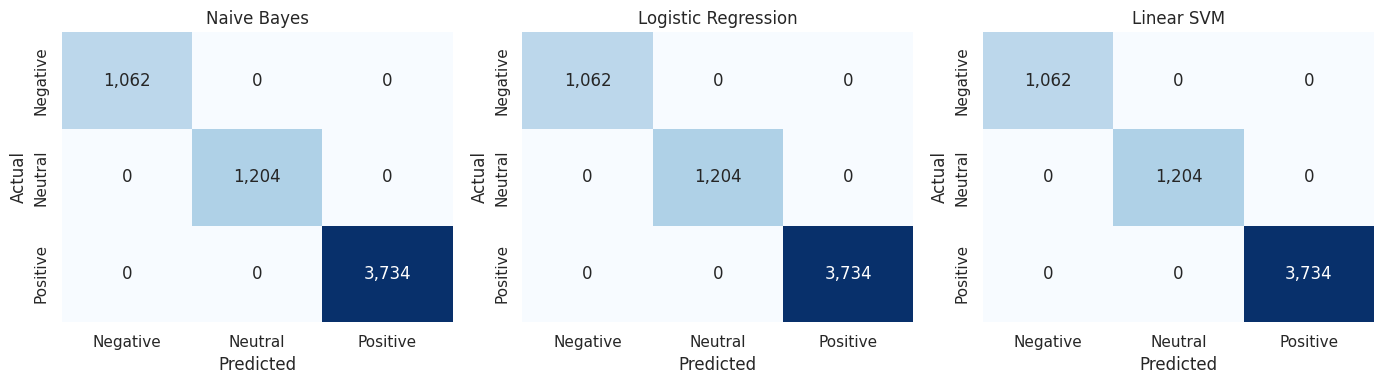

In [35]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix, classification_report
import joblib

def make_models():
    return {'Naive Bayes': MultinomialNB(), 'Logistic Regression': LogisticRegression(max_iter=1000), 'Linear SVM': LinearSVC()}
def metr(yt, yp):
    p, r, f, _ = precision_recall_fscore_support(yt, yp, average='macro', zero_division=0)
    return dict(accuracy=accuracy_score(yt, yp), precision=p, recall=r, macro_f1=f)

ML, fitted, preds = [], {}, {}
for name in make_models():
    # random split
    vec = TfidfVectorizer(ngram_range=(1, 2)); Xt = vec.fit_transform(X_tr); m = make_models()[name]
    t0 = time.time(); m.fit(Xt, y_tr); train_s = time.time() - t0
    t0 = time.time(); yp = m.predict(vec.transform(X_te)); inf_ms = (time.time() - t0) / len(y_te) * 1000
    fitted[name] = (vec, m); preds[name] = yp
    # unseen-phrase hold-out: mean over 5 random draws of held-out phrases
    hf, ha = [], []
    for d in DRAWS:
        a_, b_, _ = holdout_split(d); vec2 = TfidfVectorizer(ngram_range=(1, 2)); m2 = make_models()[name]
        m2.fit(vec2.fit_transform(X.iloc[a_]), y[a_]); hm = metr(y[b_], m2.predict(vec2.transform(X.iloc[b_]))); hf.append(hm['macro_f1']); ha.append(hm['accuracy'])
    r = metr(y_te, yp)
    ML.append(dict(model=name, **r, holdout_accuracy=np.mean(ha), holdout_macro_f1=np.mean(hf), holdout_f1_std=np.std(hf), train_sec=train_s, ms_per_review=inf_ms))
ml_df = pd.DataFrame(ML).set_index('model'); display(ml_df.round(4))
RESULTS['ml'] = ml_df.reset_index().to_dict('records')
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (name, yp) in zip(ax, preds.items()):
    sns.heatmap(confusion_matrix(y_te, yp), annot=True, fmt=',', cmap='Blues', xticklabels=ORDER, yticklabels=ORDER, ax=a, cbar=False); a.set_title(name); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
savefig('q35_ml_confusion_matrices')

### Q36. Classification report — best traditional model

In [36]:
best_ml = ml_df.sort_values(['macro_f1', 'holdout_macro_f1'], ascending=False).index[0]
print('Best traditional model (macro-F1, tie-break: unseen-phrase macro-F1):', best_ml, '\n')
print(classification_report(y_te, preds[best_ml], target_names=ORDER, digits=4))
RESULTS['best_ml_initial'] = best_ml
RESULTS['ml_report'] = classification_report(y_te, preds[best_ml], target_names=ORDER, output_dict=True)

Best traditional model (macro-F1, tie-break: unseen-phrase macro-F1): Logistic Regression 

              precision    recall  f1-score   support

    Negative     1.0000    1.0000    1.0000      1062
     Neutral     1.0000    1.0000    1.0000      1204
    Positive     1.0000    1.0000    1.0000      3734

    accuracy                         1.0000      6000
   macro avg     1.0000    1.0000    1.0000      6000
weighted avg     1.0000    1.0000    1.0000      6000



### Q37. Class imbalance

In [37]:
from sklearn.utils import resample
print('Class share in train:', {ORDER[k]: f'{(y_tr == k).mean() * 100:.1f}%' for k in range(3)}, '-> mild imbalance (Positive 62%, Neutral 20%, Negative 18%)')
def per_class_recall(yt, yp): return [round(v, 4) for v in precision_recall_fscore_support(yt, yp, labels=[0, 1, 2], zero_division=0)[1]]
def fit_eval(Xa, ya, Xb, yb, weight=None, oversample=False):
    if oversample:
        d = pd.DataFrame({'x': Xa.values, 'y': ya}); mx = d.y.value_counts().max()
        d = pd.concat([resample(g, replace=True, n_samples=mx, random_state=SEED) for _, g in d.groupby('y')]); Xa, ya = d.x, d.y.values
    p = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000, class_weight=weight)); p.fit(Xa, ya); yp = p.predict(Xb)
    return f1_score(yb, yp, average='macro'), per_class_recall(yb, yp)
rows = []
for name, kw in [('No correction', {}), ('class_weight=balanced', dict(weight='balanced')), ('Random oversampling', dict(oversample=True))]:
    f1r, rr = fit_eval(X_tr, y_tr, X_te, y_te, **kw)
    res = [fit_eval(X.iloc[a_], y[a_], X.iloc[b_], y[b_], **kw) for a_, b_, _ in (holdout_split(d) for d in DRAWS)]
    rows.append({'strategy': name, 'macroF1_random': f1r, 'macroF1_unseen_phrase': np.mean([r[0] for r in res]), 'recall_per_class_unseen (Neg/Neu/Pos)': np.mean([r[1] for r in res], axis=0).round(3).tolist()})
imb = pd.DataFrame(rows).set_index('strategy'); display(imb)
RESULTS['imbalance'] = imb.reset_index().to_dict('records')
b_f, best_s = imb.macroF1_unseen_phrase['No correction'], imb.macroF1_unseen_phrase.idxmax()
print(f'Conclusion: on the random split every strategy scores {imb.macroF1_random.min():.3f}-{imb.macroF1_random.max():.3f} (saturated), so imbalance is NOT a problem there. On unseen phrases the best strategy is "{best_s}" '
      f'(macro-F1 {imb.macroF1_unseen_phrase.max():.3f} vs {b_f:.3f} with no correction).')
if best_s == 'No correction': print('=> Re-weighting / resampling is NOT required; both variants lowered unseen-phrase performance (they push predictions away from the majority Positive class too aggressively). Keep the plain model.')
else: print(f'=> Use "{best_s}" for the production model.')

Class share in train: {'Negative': '17.7%', 'Neutral': '20.1%', 'Positive': '62.2%'} -> mild imbalance (Positive 62%, Neutral 20%, Negative 18%)


,macroF1_random,macroF1_unseen_phrase,recall_per_class_unseen (Neg/Neu/Pos)
strategy,,,
No correction,1.0,0.929820,"[0.926, 0.902, 0.964]"
class_weight=balanced,1.0,0.852636,"[0.967, 0.919, 0.801]"
Random oversampling,1.0,0.814748,"[0.959, 0.911, 0.747]"


Conclusion: on the random split every strategy scores 1.000-1.000 (saturated), so imbalance is NOT a problem there. On unseen phrases the best strategy is "No correction" (macro-F1 0.930 vs 0.930 with no correction).
=> Re-weighting / resampling is NOT required; both variants lowered unseen-phrase performance (they push predictions away from the majority Positive class too aggressively). Keep the plain model.


### Q38. Hyperparameter tuning (GridSearchCV, grouped by sentiment phrase)

In [38]:
from sklearn.model_selection import GridSearchCV
algo_grids = {
  'Naive Bayes':         (MultinomialNB(),                       {'clf__alpha': [0.1, 0.5, 1.0]}),
  'Logistic Regression': (LogisticRegression(max_iter=2000),    {'clf__C': [0.1, 1, 10, 100]}),
  'Linear SVM':          (LinearSVC(),                           {'clf__C': [0.01, 0.1, 1, 10]}),
}
est, grid = algo_grids[best_ml]
from sklearn.pipeline import Pipeline
pipe = Pipeline([('tfidf', TfidfVectorizer()), ('clf', est)])
param_grid = {'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)], 'tfidf__min_df': [1, 2], **grid}
gs = GridSearchCV(pipe, param_grid, scoring='f1_macro', cv=GroupKFold(5), n_jobs=1, refit=True)
t0 = time.time(); gs.fit(X_tr, y_tr, groups=df_clean.Review_Head.values[tr_idx]); print(f'Grid search finished in {time.time() - t0:.0f}s over {len(gs.cv_results_["params"])} configs x 5 folds')
print('Best params:', gs.best_params_); print('Best grouped-CV macro-F1:', round(gs.best_score_, 4))
tuned = gs.best_estimator_; yp_t = tuned.predict(X_te); tuned_rand = metr(y_te, yp_t)
print('Tuned model on random-split test:', {k: round(v, 4) for k, v in tuned_rand.items()})
top5 = pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score']].sort_values('mean_test_score', ascending=False).head(5); display(top5)
RESULTS['tuning'] = dict(model=best_ml, best_params={k: str(v) for k, v in gs.best_params_.items()}, cv_f1=float(gs.best_score_), test=tuned_rand)

Grid search finished in 37s over 24 configs x 5 folds
Best params: {'clf__C': 1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 2)}
Best grouped-CV macro-F1: 0.9014
Tuned model on random-split test: {'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'macro_f1': 1.0}


,params,mean_test_score
7,"{'clf__C': 1, 'tfidf__min_df': 1, 'tfidf__ngra...",0.901357
10,"{'clf__C': 1, 'tfidf__min_df': 2, 'tfidf__ngra...",0.901357
8,"{'clf__C': 1, 'tfidf__min_df': 1, 'tfidf__ngra...",0.901136
11,"{'clf__C': 1, 'tfidf__min_df': 2, 'tfidf__ngra...",0.901136
4,"{'clf__C': 0.1, 'tfidf__min_df': 2, 'tfidf__ng...",0.899538


### Q39. Most influential words

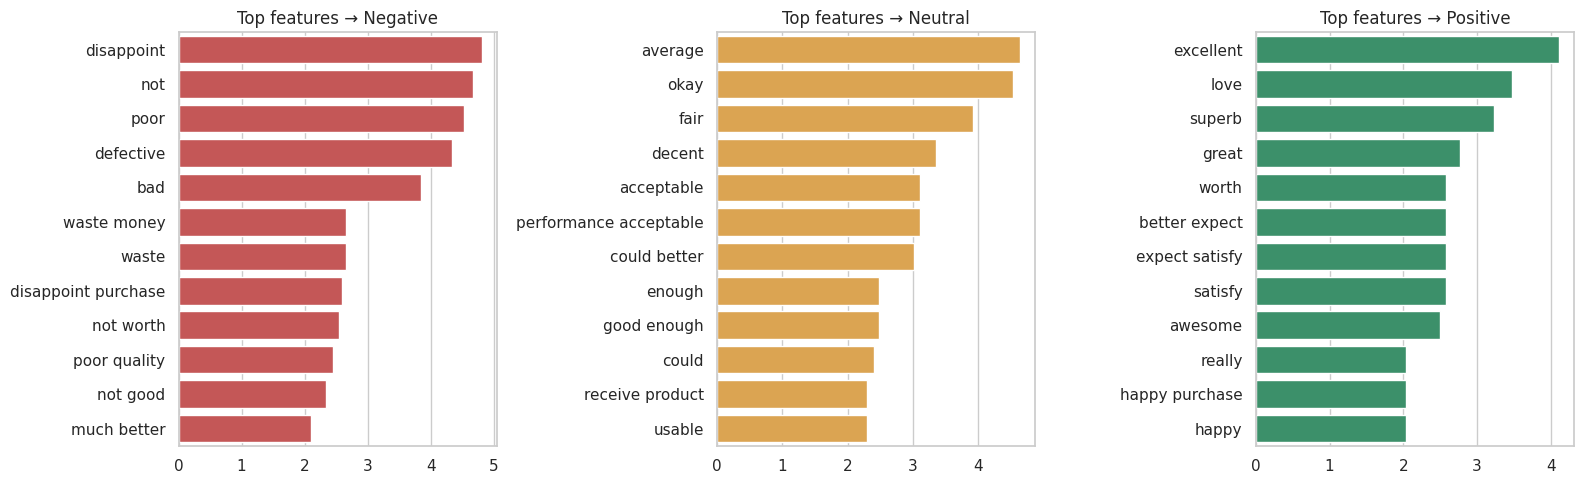

Negative → ['disappoint', 'not', 'poor', 'defective', 'bad', 'waste money', 'waste', 'disappoint purchase']
Neutral → ['average', 'okay', 'fair', 'decent', 'acceptable', 'performance acceptable', 'could better', 'enough']
Positive → ['excellent', 'love', 'superb', 'great', 'worth', 'better expect', 'expect satisfy', 'satisfy']


In [39]:
tf_v, clf = tuned.named_steps['tfidf'], tuned.named_steps['clf']
feats = np.array(tf_v.get_feature_names_out())
coefs = clf.coef_ if hasattr(clf, 'coef_') else (clf.feature_log_prob_ - clf.feature_log_prob_.mean(0))
fig, ax = plt.subplots(1, 3, figsize=(16, 5)); topfeat = {}
for k, a in enumerate(ax):
    o = np.argsort(coefs[k])[::-1][:12]; topfeat[ORDER[k]] = feats[o].tolist()
    sns.barplot(x=coefs[k][o], y=feats[o], color=COL[ORDER[k]], ax=a); a.set_title(f'Top features → {ORDER[k]}')
savefig('q39_top_features'); RESULTS['top_features'] = topfeat
for s in ORDER: print(s, '→', topfeat[s][:8])

### Q40. Save the best ML model and vectoriser

In [40]:
joblib.dump(tuned, f'{ART}/best_ml_pipeline.joblib')
joblib.dump(tuned.named_steps['tfidf'], f'{ART}/tfidf_vectorizer.joblib'); joblib.dump(tuned.named_steps['clf'], f'{ART}/best_ml_classifier.joblib')
reloaded = joblib.load(f'{ART}/best_ml_pipeline.joblib'); assert (reloaded.predict(X_te) == yp_t).all()
print('Saved + reload-verified:', {f: f'{os.path.getsize(f"{ART}/{f}") / 1024:.0f} KB' for f in os.listdir(ART)})

Saved + reload-verified: {'best_ml_pipeline.joblib': '52 KB', 'preprocessing.json': '0 KB', 'tfidf_vectorizer.joblib': '27 KB', 'best_ml_classifier.joblib': '24 KB'}


### Stress test — tuned model on unseen phrases

In [41]:
import copy
tuned_h = copy.deepcopy(tuned).fit(Xs_tr, ys_tr); yp_h = tuned_h.predict(Xs_te)
hf = []
for d in DRAWS:
    a_, b_, _ = holdout_split(d); hf.append(metr(y[b_], copy.deepcopy(tuned).fit(X.iloc[a_], y[a_]).predict(X.iloc[b_])))
ML_HOLD = {k: float(np.mean([h[k] for h in hf])) for k in hf[0]}; ML_HOLD['macro_f1_std'] = float(np.std([h['macro_f1'] for h in hf]))
print('Tuned model, unseen phrases, mean of 5 draws:', {k: round(v, 4) for k, v in ML_HOLD.items()}); print('Primary draw (42) detail:')
print(classification_report(ys_te, yp_h, target_names=ORDER, digits=4))
RESULTS['ml_tuned_holdout'] = ML_HOLD
wrong = pd.DataFrame({'text': Xs_te.values, 'actual': pd.Series(ys_te).map(dict(enumerate(ORDER))).values, 'pred': pd.Series(yp_h).map(dict(enumerate(ORDER))).values})
wrong = wrong[wrong.actual != wrong.pred]; print(f'Errors: {len(wrong)} of {len(ys_te)} ({len(wrong) / len(ys_te) * 100:.1f}%)')
display(wrong.drop_duplicates('text').head(10))
print('Confusions:', wrong.groupby(['actual', 'pred']).size().to_dict()); RESULTS['ml_holdout_confusions'] = {f'{a}->{b}': int(n) for (a, b), n in wrong.groupby(['actual', 'pred']).size().items()}

Tuned model, unseen phrases, mean of 5 draws: {'accuracy': 0.945, 'precision': 0.9385, 'recall': 0.9306, 'macro_f1': 0.9298, 'macro_f1_std': 0.0374}
Primary draw (42) detail:
              precision    recall  f1-score   support

    Negative     0.6999    0.9939    0.8214      1633
     Neutral     0.9964    0.7880    0.8800      1750
    Positive     0.9900    0.9347    0.9616      5730

    accuracy                         0.9172      9113
   macro avg     0.8954    0.9055    0.8877      9113
weighted avg     0.9392    0.9172    0.9208      9113

Errors: 755 of 9113 (8.3%)


,text,actual,pred
0,average quality neither good nor bad content u...,Neutral,Negative
2,average quality neither good nor bad clean easy,Neutral,Negative
6,amaze product totally worth price camera quali...,Positive,Negative
41,decent quality neither good nor bad content us...,Neutral,Negative
49,decent quality neither good nor bad colour loo...,Neutral,Positive
93,quality neither good nor bad installation easy,Neutral,Negative
95,fair quality neither good nor bad clean easy,Neutral,Negative
109,decent quality neither good nor bad size suitable,Neutral,Negative
112,worth value money highly recommend instruction...,Positive,Negative
113,good amaze product totally worth price instruc...,Positive,Negative


Confusions: {('Negative', 'Neutral'): 5, ('Negative', 'Positive'): 5, ('Neutral', 'Negative'): 322, ('Neutral', 'Positive'): 49, ('Positive', 'Negative'): 374}


# Phase 5 — Deep Learning

In [42]:
import tensorflow as tf
from tensorflow import keras
from keras import layers
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow', tf.__version__)

I0000 00:00:1791029916.427663    1795 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791029917.811021    1795 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


### Q41–Q42. Integer sequences, padding, vocabulary size and max length

Training vocabulary: 116 words (cap 5000 not needed) | token length mean 7.5, 99th pct 10, max 11
Chosen: VOCAB=118, MAXLEN=10 (covers 99.9% of reviews without truncation)


Example: great product perfect purchase love design practical 
  -> [10  2 43  8  9 64 63  0  0  0]
Shapes  train/val/test: (19200, 10) (4800, 10) (6000, 10)


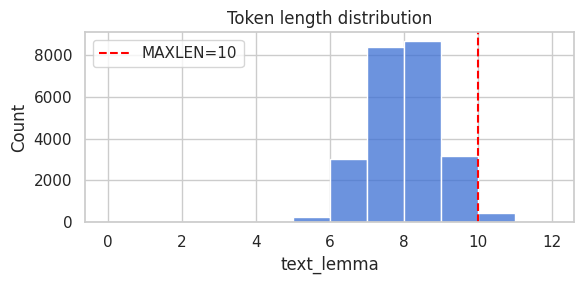

In [43]:
lens = X_tr.str.split().map(len)
MAXLEN = int(np.percentile(lens, 99)); VOCAB = min(len({w for s in X_tr for w in s.split()}) + 2, 5000)
print(f'Training vocabulary: {VOCAB - 2} words (cap 5000 not needed) | token length mean {lens.mean():.1f}, 99th pct {MAXLEN}, max {lens.max()}')
print(f'Chosen: VOCAB={VOCAB}, MAXLEN={MAXLEN} (covers {(lens <= MAXLEN).mean() * 100:.1f}% of reviews without truncation)')
def make_vectorizer(texts, maxlen=MAXLEN, vocab=VOCAB):
    v = layers.TextVectorization(max_tokens=vocab, output_sequence_length=maxlen, standardize=None, split='whitespace'); v.adapt(list(texts)); return v
def to_seq(v, texts): return v(tf.constant(list(texts))).numpy()
vec_dl = make_vectorizer(X_tr)
# validation split carved out of the training partition
dl_tr, dl_va = train_test_split(np.arange(len(tr_idx)), test_size=0.2, stratify=y_tr, random_state=SEED)
Xtr_s, Xva_s, Xte_s = to_seq(vec_dl, X_tr.iloc[dl_tr]), to_seq(vec_dl, X_tr.iloc[dl_va]), to_seq(vec_dl, X_te)
ytr_d, yva_d = y_tr[dl_tr], y_tr[dl_va]
print('Example:', X_tr.iloc[0], '\n  ->', to_seq(vec_dl, [X_tr.iloc[0]])[0]); print('Shapes  train/val/test:', Xtr_s.shape, Xva_s.shape, Xte_s.shape)
plt.figure(figsize=(6, 3)); sns.histplot(lens, bins=range(0, int(lens.max()) + 2), color='#3B6FD4'); plt.axvline(MAXLEN, c='red', ls='--', label=f'MAXLEN={MAXLEN}'); plt.legend(); plt.title('Token length distribution'); savefig('q42_sequence_lengths')
RESULTS['dl_vocab'] = int(VOCAB); RESULTS['dl_maxlen'] = int(MAXLEN)

### Q43–Q45. Embedding+Dense, LSTM and BiLSTM

In [44]:
def build(kind, vocab=VOCAB, maxlen=MAXLEN, emb=32, units=32, drop=0.3):
    inp = keras.Input(shape=(maxlen,), dtype='int32'); x = layers.Embedding(vocab, emb, mask_zero=(kind != 'dense'))(inp)
    if kind == 'dense':  x = layers.GlobalAveragePooling1D()(x); x = layers.Dense(32, activation='relu')(x)
    elif kind == 'lstm': x = layers.LSTM(units)(x)
    elif kind == 'bilstm': x = layers.Bidirectional(layers.LSTM(units))(x)
    x = layers.Dropout(drop)(x); out = layers.Dense(3, activation='softmax')(x)
    m = keras.Model(inp, out); m.compile('adam', 'sparse_categorical_crossentropy', metrics=['accuracy']); return m
def fit_dl(m, Xa, ya, Xv, yv, epochs=8, batch=128):
    cb = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)]
    t0 = time.time(); h = m.fit(Xa, ya, validation_data=(Xv, yv), epochs=epochs, batch_size=batch, callbacks=cb, verbose=0); return h.history, time.time() - t0
def eval_dl(m, Xt, yt):
    t0 = time.time(); yp = m.predict(Xt, verbose=0).argmax(1); ms = (time.time() - t0) / len(yt) * 1000; return yp, ms

DL, histories, dl_models = [], {}, {}
for name, kind in [('Embedding + Dense', 'dense'), ('LSTM', 'lstm'), ('BiLSTM', 'bilstm')]:
    tf.keras.utils.set_random_seed(SEED); m = build(kind); h, sec = fit_dl(m, Xtr_s, ytr_d, Xva_s, yva_d)
    yp, ms = eval_dl(m, Xte_s, y_te); val_f1 = f1_score(yva_d, m.predict(Xva_s, verbose=0).argmax(1), average='macro')
    histories[name], dl_models[name] = h, m
    DL.append(dict(model=name, params=m.count_params(), epochs=len(h['loss']), **metr(y_te, yp), val_macro_f1=val_f1, train_sec=sec, ms_per_review=ms))
    print(f'{name:18s} epochs={len(h["loss"])} test macro-F1={DL[-1]["macro_f1"]:.4f} train={sec:.0f}s')
dl_df = pd.DataFrame(DL).set_index('model'); display(dl_df.round(4))

Embedding + Dense  epochs=8 test macro-F1=1.0000 train=6s


LSTM               epochs=8 test macro-F1=1.0000 train=12s


BiLSTM             epochs=8 test macro-F1=1.0000 train=23s


,params,epochs,accuracy,precision,recall,macro_f1,val_macro_f1,train_sec,ms_per_review
model,,,,,,,,,
Embedding + Dense,4931,8,1.0,1.0,1.0,1.0,1.0,5.5529,0.0581
LSTM,12195,8,1.0,1.0,1.0,1.0,1.0,11.6101,0.1082
BiLSTM,20611,8,1.0,1.0,1.0,1.0,1.0,22.6385,0.2177


### Unseen-phrase hold-out for the deep-learning models (mean of 5 random draws)

In [45]:
kind_map = {'Embedding + Dense': 'dense', 'LSTM': 'lstm', 'BiLSTM': 'bilstm'}
def dl_holdout(kind, seeds, **cfg):
    f1s, accs = [], []
    for d in seeds:
        a_, b_, _ = holdout_split(d); maxlen = cfg.get('maxlen', MAXLEN)
        vh = make_vectorizer(X.iloc[a_], maxlen=maxlen); A_, B_ = to_seq(vh, X.iloc[a_]), to_seq(vh, X.iloc[b_])
        i_tr, i_va = train_test_split(np.arange(len(a_)), test_size=0.2, stratify=y[a_], random_state=SEED)
        tf.keras.utils.set_random_seed(SEED)
        m = build(kind, maxlen=maxlen, emb=cfg.get('emb', 32), units=cfg.get('units', 32), drop=cfg.get('drop', 0.3))
        fit_dl(m, A_[i_tr], y[a_][i_tr], A_[i_va], y[a_][i_va], epochs=6, batch=cfg.get('batch', 128))
        yp = m.predict(B_, verbose=0).argmax(1); f1s.append(f1_score(y[b_], yp, average='macro')); accs.append(accuracy_score(y[b_], yp))
    return np.mean(accs), np.mean(f1s), np.std(f1s)
hold_rows = []
for name, kind in kind_map.items():
    a, f, sd = dl_holdout(kind, DRAWS); hold_rows.append(dict(model=name, holdout_accuracy=a, holdout_macro_f1=f, holdout_f1_std=sd)); print(f'{name:18s} unseen-phrase macro-F1 = {f:.4f} ± {sd:.4f}')
hold_dl = pd.DataFrame(hold_rows).set_index('model'); dl_df = dl_df.join(hold_dl); display(dl_df[['accuracy', 'macro_f1', 'holdout_accuracy', 'holdout_macro_f1', 'holdout_f1_std']].round(4))

Embedding + Dense  unseen-phrase macro-F1 = 0.8335 ± 0.0560


LSTM               unseen-phrase macro-F1 = 0.9592 ± 0.0357


BiLSTM             unseen-phrase macro-F1 = 0.8806 ± 0.0258


,accuracy,macro_f1,holdout_accuracy,holdout_macro_f1,holdout_f1_std
model,,,,,
Embedding + Dense,1.0,1.0,0.8572,0.8335,0.0560
LSTM,1.0,1.0,0.9623,0.9592,0.0357
BiLSTM,1.0,1.0,0.9101,0.8806,0.0258


### Q46. Hyper-parameter experiments (one factor at a time, BiLSTM)

In [46]:
base = dict(emb=32, maxlen=MAXLEN, units=32, drop=0.3, batch=128)
grid = [('baseline', {})] + [(f'emb={v}', {'emb': v}) for v in (16, 64)] + [(f'maxlen={v}', {'maxlen': v}) for v in (8, 12)] \
     + [(f'units={v}', {'units': v}) for v in (16, 64)] + [(f'dropout={v}', {'drop': v}) for v in (0.0, 0.5)] + [(f'batch={v}', {'batch': v}) for v in (32, 256)]
exp_rows = []
for tag, ch in grid:
    cfg = {**base, **ch}; t0 = time.time()
    a, f, sd = dl_holdout('bilstm', [42, 1], **cfg)
    exp_rows.append(dict(config=tag, unseen_phrase_macro_f1=f, std_over_2_draws=sd, sec_per_run=(time.time() - t0) / 2))
exp_df = pd.DataFrame(exp_rows).set_index('config').round(4); display(exp_df); RESULTS['dl_experiments'] = exp_df.reset_index().to_dict('records')
print('Why hold-out scores? On the random validation split every configuration reaches macro-F1 = 1.000, so it cannot rank them; the unseen-phrase score can. Differences smaller than ~2x the std are noise.')

,unseen_phrase_macro_f1,std_over_2_draws,sec_per_run
config,,,
baseline,0.8874,0.0200,20.9523
emb=16,0.8496,0.0444,21.1809
emb=64,0.9413,0.0369,22.6296
maxlen=8,0.8909,0.0298,20.5824
maxlen=12,0.8874,0.0200,23.7740
units=16,0.9320,0.0592,19.2882
units=64,0.8722,0.0086,37.0182
dropout=0.0,0.9331,0.0230,21.1128
dropout=0.5,0.8430,0.0453,21.3526


Why hold-out scores? On the random validation split every configuration reaches macro-F1 = 1.000, so it cannot rank them; the unseen-phrase score can. Differences smaller than ~2x the std are noise.


### Q47. Training vs validation curves — over/under-fitting

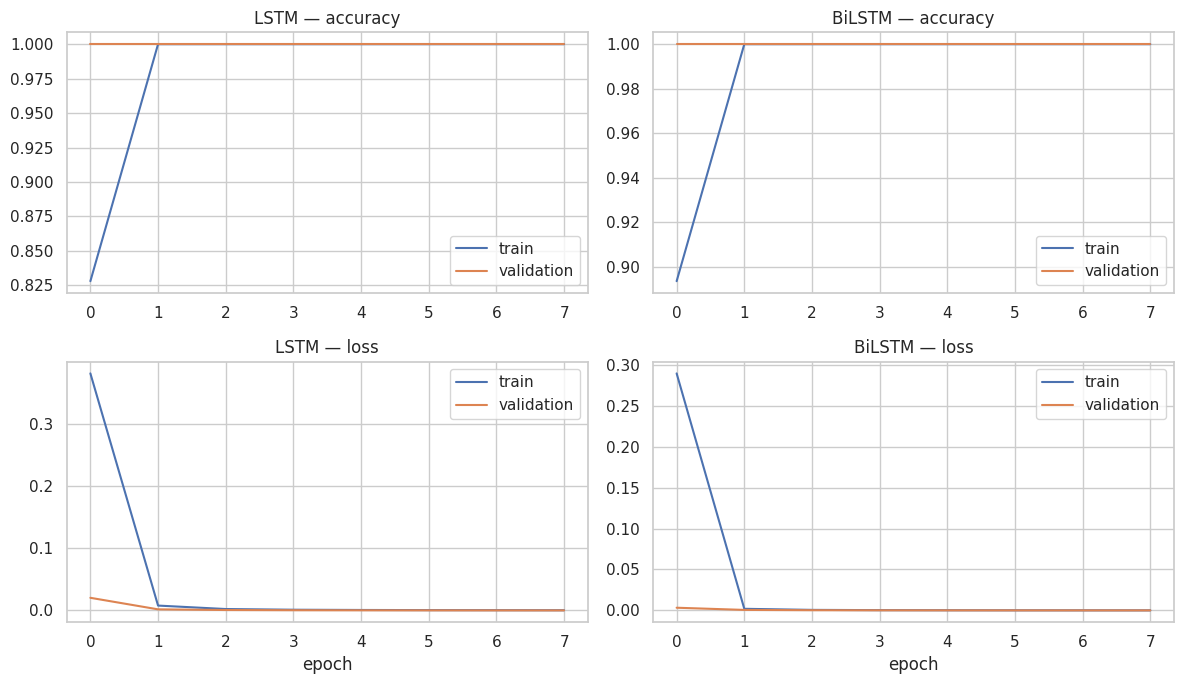

LSTM: final train acc 1.0000, val acc 1.0000, gap +0.0000, final val loss 0.0001
BiLSTM: final train acc 1.0000, val acc 1.0000, gap +0.0000, final val loss 0.0000
Diagnosis: curves converge within 1-3 epochs with a train/val gap ~0 -> no overfitting visible and no underfitting. The apparent absence of overfitting is itself a warning sign (validation data is near-duplicate of training data); the unseen-phrase hold-out below is the honest test.


In [47]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for j, name in enumerate(['LSTM', 'BiLSTM']):
    h = histories[name]
    ax[0, j].plot(h['accuracy'], label='train'); ax[0, j].plot(h['val_accuracy'], label='validation'); ax[0, j].set_title(f'{name} — accuracy'); ax[0, j].legend()
    ax[1, j].plot(h['loss'], label='train'); ax[1, j].plot(h['val_loss'], label='validation'); ax[1, j].set_title(f'{name} — loss'); ax[1, j].set_xlabel('epoch'); ax[1, j].legend()
savefig('q47_training_curves')
for name in ['LSTM', 'BiLSTM']:
    h = histories[name]; gap = h['accuracy'][-1] - h['val_accuracy'][-1]
    print(f'{name}: final train acc {h["accuracy"][-1]:.4f}, val acc {h["val_accuracy"][-1]:.4f}, gap {gap:+.4f}, final val loss {h["val_loss"][-1]:.4f}')
print('Diagnosis: curves converge within 1-3 epochs with a train/val gap ~0 -> no overfitting visible and no underfitting. The apparent absence of overfitting is itself a warning sign (validation data is near-duplicate of training data); the unseen-phrase hold-out below is the honest test.')

### Q48. Best deep-learning model — full evaluation

Best DL model (validation macro-F1, tie-break unseen-phrase macro-F1): LSTM 

              precision    recall  f1-score   support

    Negative     1.0000    1.0000    1.0000      1062
     Neutral     1.0000    1.0000    1.0000      1204
    Positive     1.0000    1.0000    1.0000      3734

    accuracy                         1.0000      6000
   macro avg     1.0000    1.0000    1.0000      6000
weighted avg     1.0000    1.0000    1.0000      6000



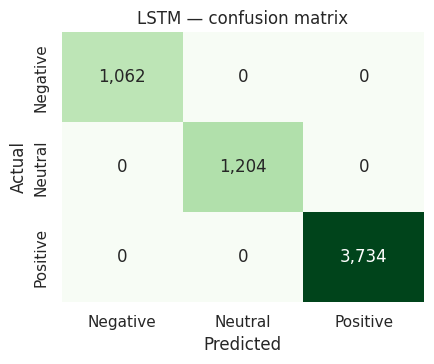

In [48]:
best_dl = dl_df.sort_values(['val_macro_f1', 'holdout_macro_f1'], ascending=False).index[0]; m_best = dl_models[best_dl]
yp_dl, ms_dl = eval_dl(m_best, Xte_s, y_te); print('Best DL model (validation macro-F1, tie-break unseen-phrase macro-F1):', best_dl, '\n')
print(classification_report(y_te, yp_dl, target_names=ORDER, digits=4))
fig, ax = plt.subplots(figsize=(4.5, 3.8)); sns.heatmap(confusion_matrix(y_te, yp_dl), annot=True, fmt=',', cmap='Greens', xticklabels=ORDER, yticklabels=ORDER, cbar=False, ax=ax); ax.set_title(f'{best_dl} — confusion matrix'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); savefig('q48_dl_confusion_matrix')
RESULTS['best_dl'] = best_dl; RESULTS['dl'] = dl_df.reset_index().to_dict('records'); RESULTS['dl_report'] = classification_report(y_te, yp_dl, target_names=ORDER, output_dict=True)

### Q49. Best traditional ML vs best deep learning

,holdout_accuracy,holdout_macro_f1,holdout_f1_std
model,,,
Embedding + Dense,0.8572,0.8335,0.0560
LSTM,0.9623,0.9592,0.0357
BiLSTM,0.9101,0.8806,0.0258


,accuracy,precision,recall,macro_f1,holdout_accuracy,holdout_macro_f1,train_sec,ms_per_review,size_kb
model,,,,,,,,,
Tuned Logistic Regression (TF-IDF),1.0,1.0,1.0,1.0,0.9450,0.9298,0.0966,0.0098,51.5820
LSTM (Keras),1.0,1.0,1.0,1.0,0.9623,0.9592,11.6101,0.1108,175.3086


,family,model,accuracy,precision,recall,macro_f1,holdout_accuracy,holdout_macro_f1
0,Traditional ML,Naive Bayes,1.0,1.0,1.0,1.0,0.6787,0.6968
1,Traditional ML,Logistic Regression,1.0,1.0,1.0,1.0,0.9450,0.9298
2,Traditional ML,Linear SVM,1.0,1.0,1.0,1.0,0.7963,0.8080
0,Deep Learning,Embedding + Dense,1.0,1.0,1.0,1.0,0.8572,0.8335
1,Deep Learning,LSTM,1.0,1.0,1.0,1.0,0.9623,0.9592
2,Deep Learning,BiLSTM,1.0,1.0,1.0,1.0,0.9101,0.8806


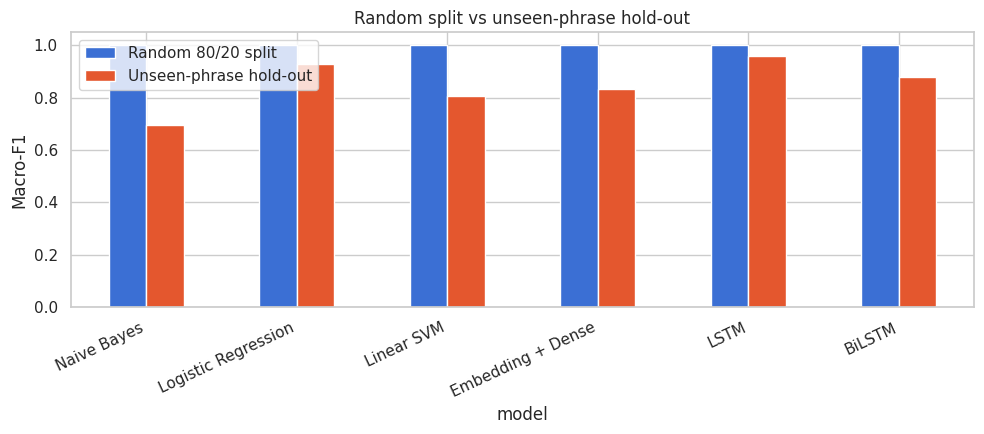

Random split : ML macro-F1 1.0000 vs DL 1.0000 (statistically indistinguishable — both saturated)
Unseen phrase: ML macro-F1 0.9298 (±0.037) vs DL 0.9592 (±0.036) -> difference 0.029; DL is ahead
Cost         : ML trains in 0.1s, 52 KB, 0.010 ms/review; DL trains in 12s, 175 KB, 0.111 ms/review


In [49]:
display(dl_df[['holdout_accuracy', 'holdout_macro_f1', 'holdout_f1_std']].round(4))
RESULTS['dl'] = dl_df.reset_index().to_dict('records')

ml_best_row = dict(model=f'Tuned {best_ml} (TF-IDF)', **tuned_rand, holdout_accuracy=ML_HOLD['accuracy'], holdout_macro_f1=ML_HOLD['macro_f1'],
                   train_sec=float(ml_df.loc[best_ml, 'train_sec']), ms_per_review=float(ml_df.loc[best_ml, 'ms_per_review']), size_kb=os.path.getsize(f'{ART}/best_ml_pipeline.joblib') / 1024)
m_best.save(f'{ART}/best_dl_model.keras')
dl_best_row = dict(model=f'{best_dl} (Keras)', **metr(y_te, yp_dl), holdout_accuracy=float(dl_df.loc[best_dl, 'holdout_accuracy']), holdout_macro_f1=float(dl_df.loc[best_dl, 'holdout_macro_f1']),
                   train_sec=float(dl_df.loc[best_dl, 'train_sec']), ms_per_review=ms_dl, size_kb=os.path.getsize(f'{ART}/best_dl_model.keras') / 1024)
final = pd.DataFrame([ml_best_row, dl_best_row]).set_index('model'); display(final.round(4))

# one common comparison table for everything
allm = pd.concat([ml_df.reset_index().assign(family='Traditional ML'), dl_df.reset_index().assign(family='Deep Learning')])
common = allm[['family', 'model', 'accuracy', 'precision', 'recall', 'macro_f1', 'holdout_accuracy', 'holdout_macro_f1']].round(4); common.to_csv('model_comparison.csv', index=False); display(common)
RESULTS['final_compare'] = final.reset_index().to_dict('records'); RESULTS['common'] = common.to_dict('records')

fig, ax = plt.subplots(figsize=(10, 4.5)); cm_ = common.set_index('model')[['macro_f1', 'holdout_macro_f1']]
cm_.plot(kind='bar', ax=ax, color=['#3B6FD4', '#E4572E']); ax.set_ylim(0.0, 1.05); ax.set_ylabel('Macro-F1'); ax.set_title('Random split vs unseen-phrase hold-out'); ax.legend(['Random 80/20 split', 'Unseen-phrase hold-out']); plt.xticks(rotation=25, ha='right'); savefig('q49_model_comparison')

ml_h, dl_h = ML_HOLD['macro_f1'], float(dl_df.loc[best_dl, 'holdout_macro_f1'])
print(f'Random split : ML macro-F1 {tuned_rand["macro_f1"]:.4f} vs DL {metr(y_te, yp_dl)["macro_f1"]:.4f} (statistically indistinguishable — both saturated)')
print(f'Unseen phrase: ML macro-F1 {ml_h:.4f} (±{ML_HOLD["macro_f1_std"]:.3f}) vs DL {dl_h:.4f} (±{float(dl_df.loc[best_dl, "holdout_f1_std"]):.3f}) -> difference {abs(ml_h - dl_h):.3f}; {"ML" if ml_h > dl_h else "DL"} is ahead')
print(f'Cost         : ML trains in {ml_best_row["train_sec"]:.1f}s, {ml_best_row["size_kb"]:.0f} KB, {ml_best_row["ms_per_review"]:.3f} ms/review; DL trains in {dl_best_row["train_sec"]:.0f}s, {dl_best_row["size_kb"]:.0f} KB, {dl_best_row["ms_per_review"]:.3f} ms/review')

### Q50. Sentiment prediction pipeline (new review → label + confidence)

In [50]:
# Persist DL vocabulary so the model can be rebuilt without retraining
json.dump({'vocabulary': vec_dl.get_vocabulary(), 'maxlen': int(MAXLEN), 'best_dl': best_dl, 'text_col': TEXT_COL}, open(f'{ART}/dl_tokenizer.json', 'w'))
from sklearn.calibration import CalibratedClassifierCV
ml_final = joblib.load(f'{ART}/best_ml_pipeline.joblib')
if not hasattr(ml_final, 'predict_proba'):            # LinearSVC -> calibrate to obtain real probabilities
    ml_final = CalibratedClassifierCV(ml_final, cv=3).fit(X_tr, y_tr); joblib.dump(ml_final, f'{ART}/best_ml_pipeline_calibrated.joblib')

def predict_sentiment(review_text, review_summary='', engine='ml'):
    """Return (label, confidence, probabilities) for a new review. engine: 'ml' | 'dl'."""
    txt = nu.build_variant(nu.combine(review_summary, review_text), TEXT_COL)
    if engine == 'ml': p = ml_final.predict_proba([txt])[0]
    else: p = m_best.predict(to_seq(vec_dl, [txt]), verbose=0)[0]
    k = int(np.argmax(p)); return ORDER[k], float(p[k]), {ORDER[i]: round(float(p[i]), 3) for i in range(3)}

demo = [
 ('Loved it', 'Perfect purchase, loved it, battery life is decent.', 'Positive'),
 ('Average', 'Decent product but nothing special, size was accurate.', 'Neutral'),
 ('Waste of money', 'Product stopped working after a few days.', 'Negative'),
 ('', 'The phone is amazing, the camera is outstanding and the battery easily lasts a full day.', 'Positive'),
 ('', 'Terrible. It stopped charging within a week and customer support was useless.', 'Negative'),
 ('', "It's okay I guess, does the job but nothing to write home about.", 'Neutral'),
 ('', 'Not good at all, would not buy again.', 'Negative'),
 ('Great product', 'Very good quality but delivery was late and packaging was damaged.', 'Mixed'),
]
rows = []
for s, t, truth in demo:
    ml_l, ml_c, _ = predict_sentiment(t, s, 'ml'); dl_l, dl_c, _ = predict_sentiment(t, s, 'dl')
    rows.append({'review': (s + ' | ' if s else '') + t[:70], 'expected': truth, 'ML': f'{ml_l} ({ml_c:.0%})', 'DL': f'{dl_l} ({dl_c:.0%})'})
demo_df = pd.DataFrame(rows); display(demo_df); RESULTS['demo'] = demo_df.to_dict('records')
print('\nInteractive use (uncomment):\n# txt = input("Enter a Flipkart review: "); print(predict_sentiment(txt))')

,review,expected,ML,DL
0,"Loved it | Perfect purchase, loved it, battery...",Positive,Positive (99%),Positive (100%)
1,"Average | Decent product but nothing special, ...",Neutral,Neutral (99%),Neutral (100%)
2,Waste of money | Product stopped working after...,Negative,Negative (100%),Negative (100%)
3,"The phone is amazing, the camera is outstandin...",Positive,Positive (60%),Positive (100%)
4,Terrible. It stopped charging within a week an...,Negative,Negative (78%),Negative (100%)
5,"It's okay I guess, does the job but nothing to...",Neutral,Neutral (99%),Neutral (100%)
6,"Not good at all, would not buy again.",Negative,Negative (100%),Negative (100%)
7,Great product | Very good quality but delivery...,Mixed,Negative (63%),Positive (100%)



Interactive use (uncomment):
# txt = input("Enter a Flipkart review: "); print(predict_sentiment(txt))


In [51]:
# Save all results for the report / slides
RESULTS['best_ml'] = best_ml
json.dump(RESULTS, open('results.json', 'w'), indent=2, default=lambda o: float(o) if hasattr(o, '__float__') else str(o))
print('Artifacts:', sorted(os.listdir(ART))); print('Figures  :', len(os.listdir(FIG)), 'PNG files')

Artifacts: ['best_dl_model.keras', 'best_ml_classifier.joblib', 'best_ml_pipeline.joblib', 'dl_tokenizer.json', 'preprocessing.json', 'tfidf_vectorizer.joblib']
Figures  : 18 PNG files


# Findings, limitations and future scope
* **Leakage:** `Rating` and `Sentiment_Score` determine the label exactly; they must never be features. Every model here uses text only.
* **Data realism:** 30,000 reviews are built from only 30 sentiment phrases × 32 aspect phrases, so random-split scores (~100 %) overstate real-world performance. The unseen-phrase hold-out is the credible number.
* **Out-of-template text:** see the Q50 demo — genuinely new wording, negation and mixed reviews expose the limits of a model trained on templates.
* **Future scope:** train on real Flipkart reviews, add pretrained embeddings (Word2Vec/FastText), fine-tune BERT / Sentence-BERT, add aspect-level sentiment, SHAP/LIME explanations and a Streamlit demo.